# **Actividad | Dataset - Notebook (Semana 3)**
### **Maestría en Inteligencia Artificial Aplicada**
### **Curso: TC5061 - Operaciones de aprendizaje automático**
#### **Tecnológico de Monterrey**
#### **Docente titular: Dr. Iván Reyes Amezcua**

*   **Nombre del estudiante:** Andrés Eduardo Vázquez Pérez
*   **Matrícula:** A01225190

En esta actividad, se recorre el flujo básico de un proyecto de Machine Learning: cargar y describir el dataset, análisis exploratorio (EDA), limpieza de los datos, entrenar un modelo base, evaluar el modelo y registrar el experimento en MLflow. El objetivo de las instrucciones es no lograr el mejor modelo posible, sino dejar un punto de partida reproducible.

**Problema seleccionado:** regresión. Con los datos de un seguro médico quiero predecir el costo médico individual (`charges`) a partir de las características de cada persona.

# **Paso 1: Carga y describe el dataset**

Uso el dataset "Medical Cost Personal Datasets" de Kaggle (https://www.kaggle.com/datasets/mirichoi0218/insurance)

In [1]:
# Importamos las librerias que se usan en el notebook
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from dotenv import load_dotenv
from mlflow.models import ModelSignature
from mlflow.types import Schema, ColSpec

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import kagglehub
from kagglehub import KaggleDatasetAdapter

In [2]:
# Cargamos el dataset en un dataframe de pandas desde kaggle

# Se carga la última versión desde Kaggle directamente (Paso 1-"Importa los datos en un notebook"):
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "mirichoi0218/insurance",
    "insurance.csv",
)

print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Se analiza con info: columnas, tipos de dato y valores no nulos (Paso 1-"Describe su estructura (número de registros, variables, tipos y significado)")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### Estructura del dataset

El dataset tiene **1338 registros y 7 variables** (6 de entrada y 1 de salida/target). Cada registro representa a una persona asegurada.

| Variable | Tipo | Significado |
| --- | --- | --- |
| `age` | numérico (discreto) | Edad de la persona asegurada, en años |
| `sex` | categórica | Sexo del asegurado (`female`, `male`) |
| `bmi` | numérico (continuo) | Índice de masa corporal (kg/m2) |
| `children` | numérico (discreto) | Número de hijos o dependientes cubiertos por el seguro |
| `smoker` | categórica | Si la persona fuma (`yes`, `no`) |
| `region` | categórica | Región residencial en Estados Unidos (`northeast`, `northwest`, `southeast`, `southwest`) |
| `charges` | numérico (continuo) | **Variable objetivo.** Costos médicos individuales facturados por el seguro, en dólares |

Como la variable a predecir es numérica y continua, se trata de un problema de **regresión**. Con `info()` observo 4 columnas numéricas (`age`, `bmi`, `children`, `charges`) y 3 categóricas (`sex`, `smoker`, `region`).

# **Paso 2: Realiza un análisis exploratorio (EDA)**

### Estadísticas descriptivas

In [4]:
# Estadísticas de las variables numéricas 
# (Paso 2 -"Genera estadísticas descriptivas que te permitan entender la distribución de las variables y las relaciones entre ellas")
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


In [5]:
# Estadísticas de las variables categóricas
display(df.describe(include='object').T)

# Frecuencia absoluta y proporción de cada categoría
for col in ['sex', 'smoker', 'region']:
    print(f'\nVariable: {col}')
    
    resumen = pd.DataFrame({
        'frecuencia': df[col].value_counts(),
        'proporcion': df[col].value_counts(normalize=True).round(3)
    })
    
    display(resumen)

,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364



Variable: sex


,frecuencia,proporcion
sex,,
male,676,0.505
female,662,0.495



Variable: smoker


,frecuencia,proporcion
smoker,,
no,1064,0.795
yes,274,0.205



Variable: region


,frecuencia,proporcion
region,,
southeast,364,0.272
southwest,325,0.243
northwest,325,0.243
northeast,324,0.242


La edad va de 18 a 64 años (media de 39) y el BMI tiene una media de 30.66. `charges` tiene una media de 13,270.42 dólares y una mediana de 9,382.03, con un máximo de 63,770.43, lo que indica una distribución con posible sesgo a la derecha. Las categorías de `sex` y `region` están casi balanceadas, mientras que solo 20% de las personas son fumadoras.

### Distribución de la variable objetivo y de las variables numéricas

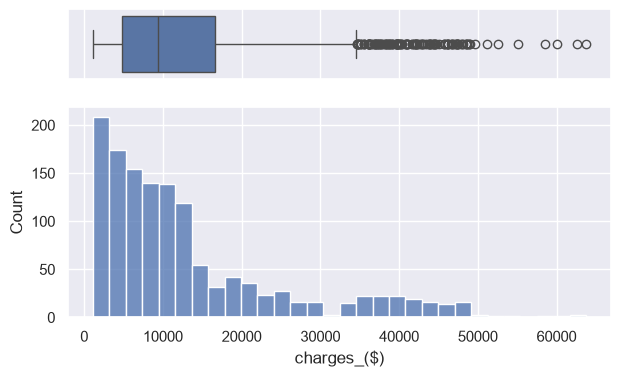

In [6]:
# Distribución de charges con histograma y boxplot
# (Paso 2 -"Genera visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas")
sns.set(rc={'figure.figsize':(7,4)})
f, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.25, .75)})
sns.boxplot(x=df['charges'], ax=ax_box)
sns.histplot(data=df, x='charges', ax=ax_hist)
ax_box.set(xlabel='')
ax_hist.set(xlabel='charges_($)')
plt.show()

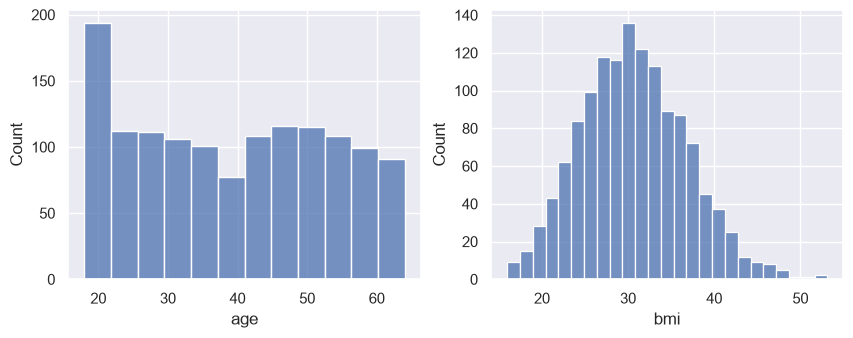

In [7]:
# Distribución de age y bmi con histogramas
fig, axes = plt.subplots(1, 2, figsize=(10,3.5))
sns.histplot(data=df, x='age', ax=axes[0])
sns.histplot(data=df, x='bmi', ax=axes[1])
plt.show()

`charges` tiene sesgo positivo a la derecha: la mayoría de los costos está por debajo de 20,000 dólares y hay una cola larga hacia costos altos que el boxplot destaca como valores atípicos/outliers. `bmi` tiene forma acampanada centrada cerca de 30, y `age` es casi uniforme, con más registros en los 18 y 19 años.

### Relaciones entre variables

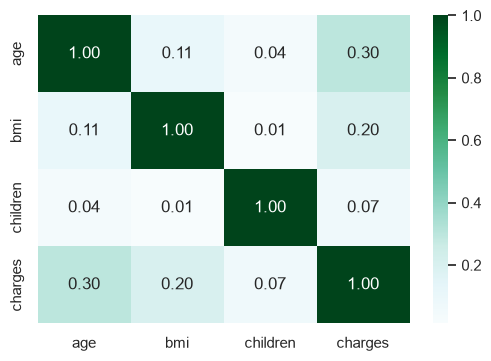

In [8]:
# Matriz de correlación entre las variables numéricas
sns.set(rc={'figure.figsize':(6,4)})
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='BuGn')
plt.show()

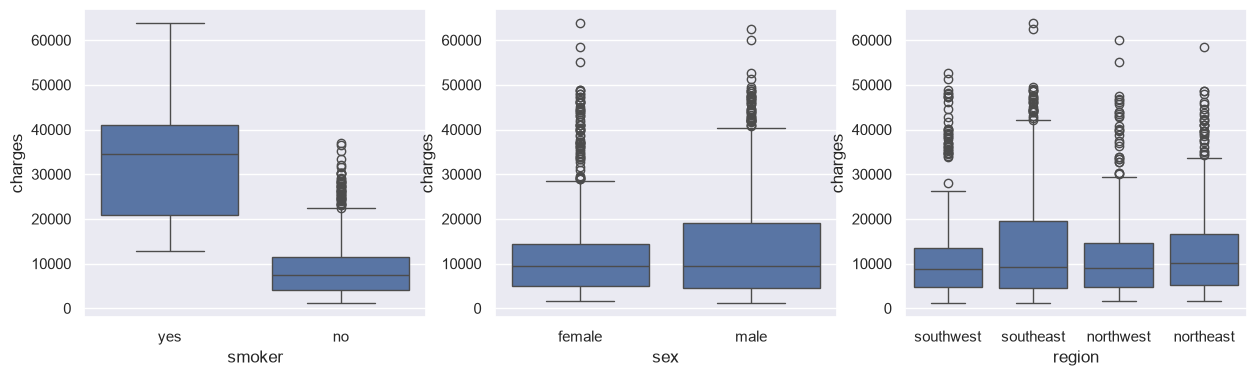

In [9]:
# charges según smoker, sex y region
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0])
sns.boxplot(data=df, x='sex', y='charges', ax=axes[1])
sns.boxplot(data=df, x='region', y='charges', ax=axes[2])
plt.show()

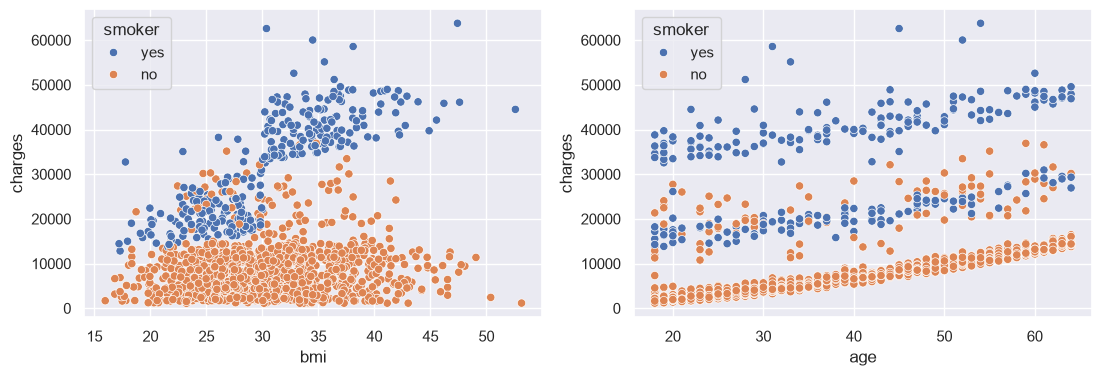

In [10]:
# charges contra bmi y contra age, separando por smoker
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', ax=axes[0])
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', ax=axes[1])
plt.show()

In [11]:
# Promedio de charges por grupo de smoker
df.groupby('smoker')['charges'].agg(['mean', 'median', 'count']).round(2)

,mean,median,count
smoker,,,
no,8434.27,7345.41,1064
yes,32050.23,34456.35,274


**Hallazgos del EDA:**

*   La correlación de `charges` con las variables numéricas es baja: 0.30 con `age`, 0.20 con `bmi` y 0.07 con `children`. Además, las variables casi no se correlacionan entre sí (la mayor es 0.11), así que no hay señales de multicolinealidad.
*   `smoker` es la variable que más separa los costos: los fumadores tienen un costo promedio de 32,050.23 dólares contra 8,434.27 de los no fumadores, casi 4 veces más.
*   En las gráficas de dispersión se ven grupos: `charges` crece con `age`, y en `bmi` los fumadores con BMI mayor a 30 concentran los costos más altos. Se identifica una relación entre `smoker` y `bmi` que se logra identifcar con el scatterplot.
*   `sex` y `region` casi no cambian la distribución de `charges`.

# **Paso 3: Limpia los datos**

Se revisa cuatro problemas de calidad: valores faltantes, duplicados, tipos incorrectos y outliers. Se documenta cada decisión de limpieza.

### 3.1 Valores faltantes

In [12]:
# Valores faltantes por feature/variable
# (Paso 3-"Identifica y trata valores faltantes")
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**Decisión:** ninguna columna tiene valores faltantes, por lo tanto no hace falta imputar ni eliminar registros.

### 3.2 Registros duplicados

In [13]:
# Registros duplicados y su detalle de cada variable
# (Paso 3-"Identifica y trata valores duplicados")
print('Registros duplicados:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Registros duplicados: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


**Decisión:** hay 1 registro duplicado (dos filas idénticas en todas las variables, incluida `charges`). Teniendo solo 7 variables poder tener una repetición exacta es posible en un caso real, pero no puedo confirmar que sean dos personas distintas con los datos que tengo, por lo que conservar ambas filas haría que el mismo caso pese doble y podría quedar una copia en entrenamiento y otra en prueba ocasionando data leakage. Dicho esto, elimino la copia y conservo la primera aparición.

In [14]:
# Se elimina el duplicado y se reinicia el índice
df = df.drop_duplicates().reset_index(drop=True)
print('Registros duplicados:', df.duplicated().sum())
print('Dimensión final:', df.shape)

Registros duplicados: 0
Dimensión final: (1337, 7)


### 3.3 Tipos de datos

In [15]:
# Revisamos los tipos y que los valores de las categóricas sean los esperados
# (paso 3-"Identifica y trata tipos incorrectos.")
print(df.dtypes)
for col in ['sex', 'smoker', 'region']:
    print(col, df[col].unique())

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
sex ['female' 'male']
smoker ['yes' 'no']
region ['southwest' 'southeast' 'northwest' 'northeast']


**Decisión:** las variables numéricas ya tienen el tipo correcto (`int64` y `float64`). Las tres categóricas están como `object` y sus etiquetas son coherentes (sin mayúsculas mezcladas, espacios ni errores de captura), así que no hay correcciones de texto. Las dejo como `object` porque más adelante el `OneHotEncoder` las codificará dentro del pipeline del modelo.

### 3.4 Outliers

In [16]:
# Detección de outliers con el rango intercuartílico (IQR) en las variables numéricas
# (paso 3-"Identifica y trata outliers.")
for col in ['age', 'bmi', 'children', 'charges']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    BM = (df[col] > (Q3 + 1.5 * IQR)) | (df[col] < (Q1 - 1.5 * IQR))
    print(col, '->', BM.sum(), 'outliers')

age -> 0 outliers
bmi -> 9 outliers
children -> 0 outliers
charges -> 139 outliers


In [17]:
# Los outliers de charges, ¿son fumadores?
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
BM = df['charges'] > (Q3 + 1.5 * IQR)
print(df[BM]['smoker'].value_counts())
df[BM].head()

smoker
yes    136
no       3
Name: count, dtype: int64


,age,sex,bmi,children,smoker,region,charges
14,27,male,42.13,0,yes,southeast,39611.7577
19,30,male,35.30,0,yes,southwest,36837.4670
23,34,female,31.92,1,yes,northeast,37701.8768
29,31,male,36.30,2,yes,southwest,38711.0000
30,22,male,35.60,0,yes,southwest,35585.5760


**Decisión:** el método IQR marca 139 outliers en `charges` y 9 en `bmi` (`age` y `children` no tienen). Los de `charges` son costos altos pero posibles, y 136 de los 139 corresponden a personas fumadoras, es decir, son casos reales que el modelo debe aprender a predecir, no errores de captura. Los de `bmi` (hasta su max 53.13) son valores extremos pero plausibles. Como no hay evidencia de que sean errores y eliminarlos quitaría justo los casos más caros, **los conservo**. Se tiene presente que la regresión lineal es sensible a estos valores, por lo que se tomará en cuenta al interpretar el error del modelo.

# **Paso 4: Entrena un modelo base**

Como baseline elijo una **regresión lineal múltiple** (`LinearRegression`): es sencilla, no requiere ajustar hiperparámetros y es apropiada para una variable objetivo continua, por lo que sirve como punto de comparación para modelos más complejos.

Las variables categóricas (`sex`, `smoker`, `region`) las convierto con `OneHotEncoder` dentro de un `ColumnTransformer` y las numéricas pasan sin cambios (la regresión lineal no requiere escalamiento). Todo va dentro de un `Pipeline`, de modo que la transformación se ajusta solo con los datos de entrenamiento y evito filtrado de información (data leakage).

In [18]:
# Variables de entrada (X) y variable de salida/target (y)
X = df.drop(columns='charges')
y = df['charges']

# División 80% entrenamiento y 20% prueba, con semilla para que sea reproducible
# (Parte 4-"Divide los datos en entrenamiento y prueba.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)

Entrenamiento: (1069, 6) | Prueba: (268, 6)


In [19]:
# Columnas categóricas y numéricas
cat_features = ['sex', 'smoker', 'region']
num_features = ['age', 'bmi', 'children']

# Preprocesamiento: one-hot para las categóricas (drop='first' para evitar la colinealidad) y las numéricas pasan sin transformación
preprocessing = ColumnTransformer(transformers=[('cat', OneHotEncoder(drop='first'), cat_features),('num', 'passthrough', num_features)])

# Pipeline con el preprocesamiento y el modelo base 
# (Parte 4-"Selecciona un modelo sencillo (baseline) apropiado para el problema.")
model = Pipeline(steps=[('preprocessing', preprocessing),
                        ('regressor', LinearRegression())])

# Entrenamos solo con los datos de entrenamiento
# (Parte 4-"Entrénalo.")
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with

# **Paso 5: Evalúa el modelo**

Como es un problema de regresión uso dos métricas, ambas en dólares (la misma unidad que `charges`): el **RMSE** (raíz del error cuadrático medio), que penaliza más los errores grandes, y el **MAE** (error absoluto medio), que es el error promedio en valor absoluto.

Como complemento agrego el **R²** (coeficiente de determinación), que no está en dólares: indica qué proporción de la variación de `charges` logra explicar el modelo, donde 1 sería un ajuste perfecto y 0 equivale a predecir siempre el promedio.

In [20]:
# Predicciones sobre el conjunto de prueba y cálculo de las métricas
y_pred = model.predict(X_test)

# (Paso 5-"Calcula al menos una métrica de desempeño coherente con el tipo de problema.")
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('RMSE:', round(rmse, 2))
print('MAE:', round(mae, 2))
print('R2:', round(r2, 2))

# Referencias para interpretar el error
print('Promedio de charges en prueba:', round(y_test.mean(), 2))
print('Desviación estándar de charges en prueba:', round(y_test.std(), 2))

RMSE: 5956.34
MAE: 4177.05
R2: 0.81
Promedio de charges en prueba: 14272.01
Desviación estándar de charges en prueba: 13581.03


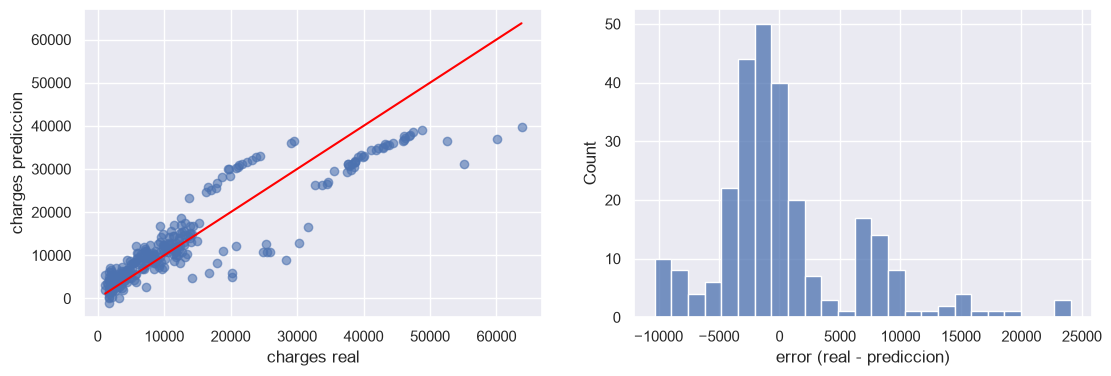

In [21]:
# Valores reales contra predicciones y errores de predicción
# (Paso 5-"Interpreta el resultado de manera detallada.")
fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].scatter(y_test, y_pred, alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
axes[0].set_xlabel('charges real')
axes[0].set_ylabel('charges prediccion')
sns.histplot(y_test - y_pred, ax=axes[1])
axes[1].set_xlabel('error (real - prediccion)')
plt.show()

### Interpretación

*   **RMSE = 5,956.34 dólares:** la raíz del error cuadrático medio es de 5,956.34 dólares por persona. Es menos de la mitad de la desviación estándar de `charges` en prueba (13,581), o sea que el modelo sí aprende algo real.
*   **MAE = 4,177.05 dólares:** el error absoluto medio es de unos 4,177.05 dólares, alrededor de 29% del costo promedio en prueba (14,272.01). Sigue siendo un error alto para usarlo en decisiones de precio, pero es coherente para un baseline.
*   **R^2 = 0.81:** el modelo explica aproximadamente 81% de la variación de `charges` en el conjunto de prueba, el 19% restante de la variación queda sin explicar, lo cual coincide con los errores grandes en los costos altos.
*   **RMSE es mayor que MAE:** Esto es porque hay errores grandes que pesan más al elevarse al cuadrado. La gráfica de reales contra predicciones lo confirma: los puntos se alejan de la línea roja en los costos altos, justo los fumadores y personas con BMI alto que vimos en el EDA, y el histograma de errores muestra una cola larga a la derecha.
*   **Limitación:** La regresión lineal no captura relaciones no lineales ni posibles interacciones entre variables, como el efecto conjunto de `smoker` y `bmi` sobre charges. Además, con los outliers que conservé en el paso 3 de limpieza, los errores más grandes se concentran en los costos altos. Incluso hay predicciones negativas, algo que es imposible para un costo.
*   Estos valores son mi **punto de partida baseline (línea base)**: un modelo posterior solo será mejor si logra un RMSE y un MAE menores en el mismo conjunto de prueba.

# **Paso 6: Registro del experimento en MLflow**

Antes de correr la siguiente celda levanto el servidor de tracking en una terminal, con el entorno virtual activado y desde la raíz del proyecto:

```
mlflow ui --port 5001
```

In [22]:
# Conexión con el servidor de tracking de MLflow
load_dotenv(dotenv_path="../.env")
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5001")) #Se usa 5001 porque en mi Mac el puerto 5000 es utilizado por AirPlay

# Seleccionamos (o creamos) el experimento (por eso sale la observación cuando no existe y se crea)
mlflow.set_experiment("Medical_Cost_Baseline")

2026/10/02 14:02:30 INFO mlflow.tracking.fluent: Experiment with name 'Medical_Cost_Baseline' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/793304507838875862', creation_time=1790971350645, experiment_id='793304507838875862', last_update_time=1790971350645, lifecycle_stage='active', name='Medical_Cost_Baseline', tags={}>

In [ ]:
# Parámetros de la configuración del modelo y del preprocesamiento
params = {
    "model": "LinearRegression",
    "test_size": 0.2,
    "random_state": 42,
    "encoder": "OneHotEncoder(drop='first')",
    "cat_features": ", ".join(cat_features),
    "num_features": ", ".join(num_features),
    "n_train": X_train.shape[0],
    "n_test": X_test.shape[0],
}

with mlflow.start_run(run_name="linear_regression_baseline"):

    # Capturamos parámetros y métricas para mlflow:
    # (Paso 6-"Usa MLFlow Tracking para registrar parámetros y métricas.")
    mlflow.log_params(params)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)

    # Capturamos artefacto mlfow: reporte de las métricas en un archivo de texto
    # (Paso 6-"Solo si aplica, registra los artefactos del modelo base.")
    salidas = Path("salidas")
    salidas.mkdir(exist_ok=True)
    reporte = salidas / "reporte_regresion.txt"
    reporte.write_text(f"Modelo: LinearRegression\nRMSE: {rmse:.2f}\nMAE: {mae:.2f}\nR2: {r2:.2f}\n")
    mlflow.log_artifact(str(reporte))

    # Capturamos modelo base en mlflow con su firma y un ejemplo de entrada, registrado en el Model Registry
    # Se hace una firma de esquema manual declarada para conservar age y children como enteros (evita el warning de esquema inferido)
    signature = ModelSignature(
        inputs=Schema([ColSpec("long", "age"), ColSpec("string", "sex"), ColSpec("double", "bmi"),
                       ColSpec("long", "children"), ColSpec("string", "smoker"), ColSpec("string", "region")]),
        outputs=Schema([ColSpec("double")]))
    mlflow.sklearn.log_model(sk_model=model, name="linear_regression_model",
                             signature=signature, input_example=X_train.head(3),
                             registered_model_name="medical_cost_baseline",
                             serialization_format="cloudpickle")

Successfully registered model 'medical_cost_baseline'.
2026/10/02 14:02:32 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: medical_cost_baseline, version 1


🏃 View run linear_regression_baseline at: http://localhost:5001/#/experiments/793304507838875862/runs/960832ea2ca0423b9ee7245d58d0f1b1
🧪 View experiment at: http://localhost:5001/#/experiments/793304507838875862


Created version '1' of model 'medical_cost_baseline'.


### Evidencia en la interfaz de MLflow

Abro la interfaz en `http://localhost:5001`, en el experimento **Medical_Cost_Baseline**. El run **linear_regression_baseline** aparece con sus parámetros, sus métricas `rmse`, `mae` y `R^2`, el reporte `reporte_regresion.txt` en Artifacts y el modelo base registrado como **medical_cost_baseline** en la sección Models.

*Capturas de la interfaz de MLflow:*
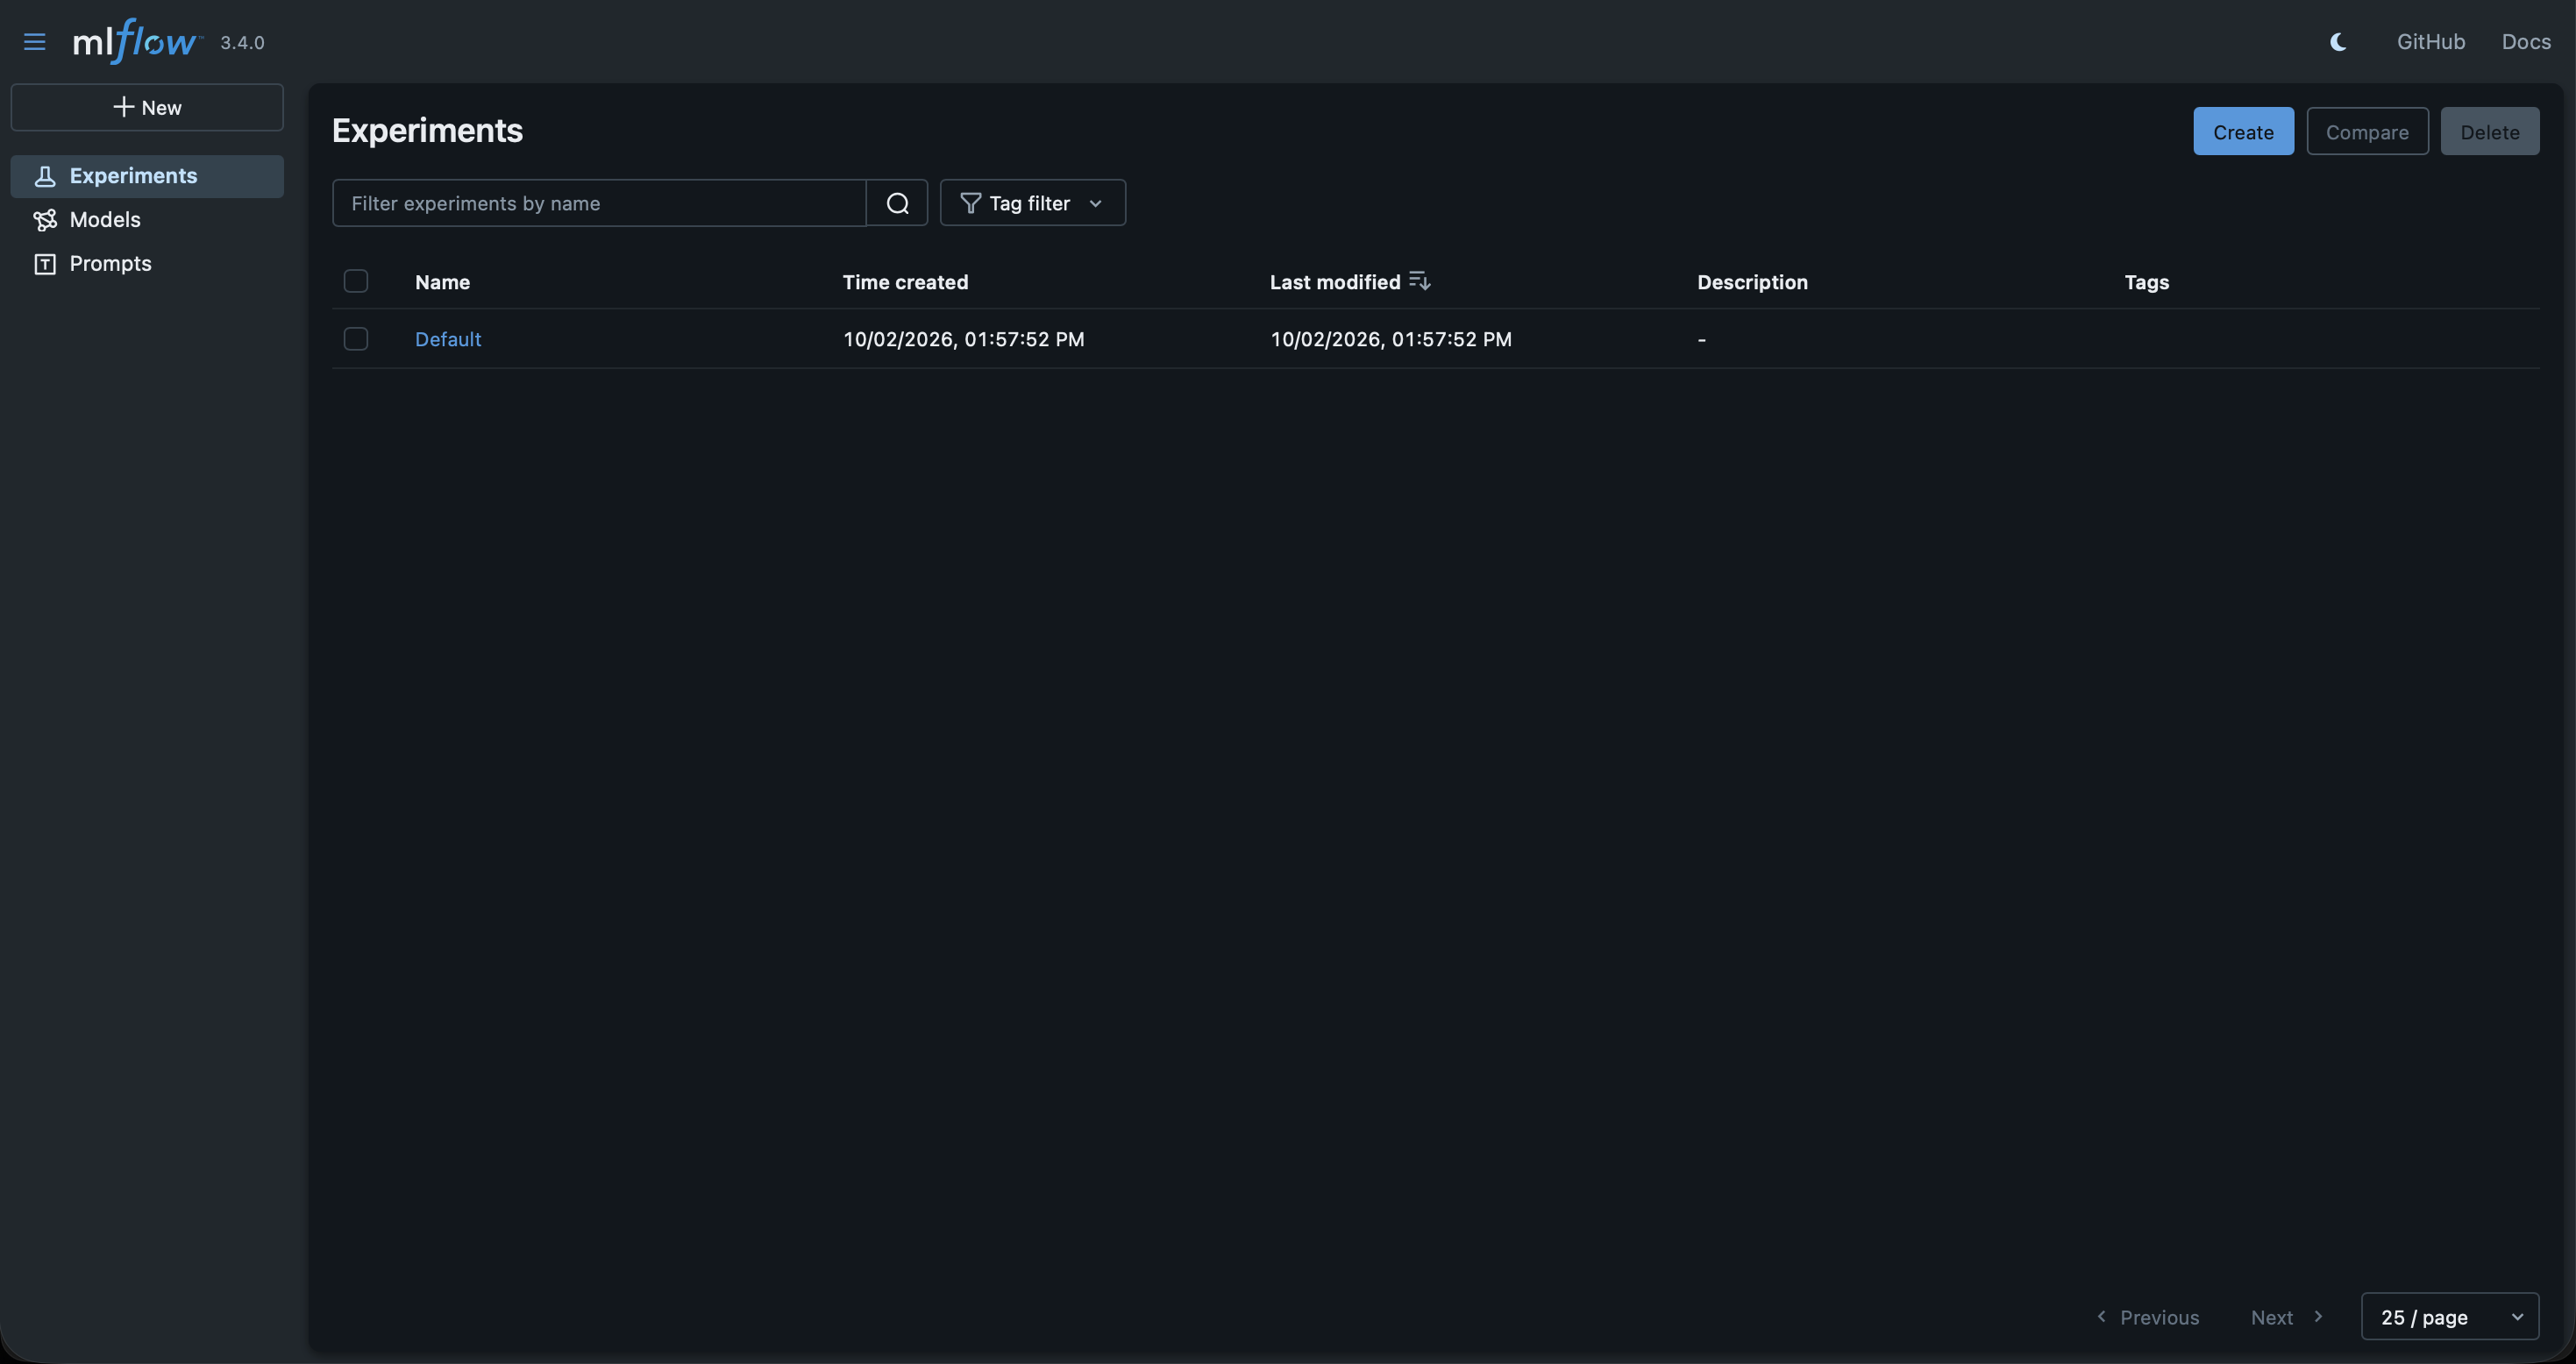
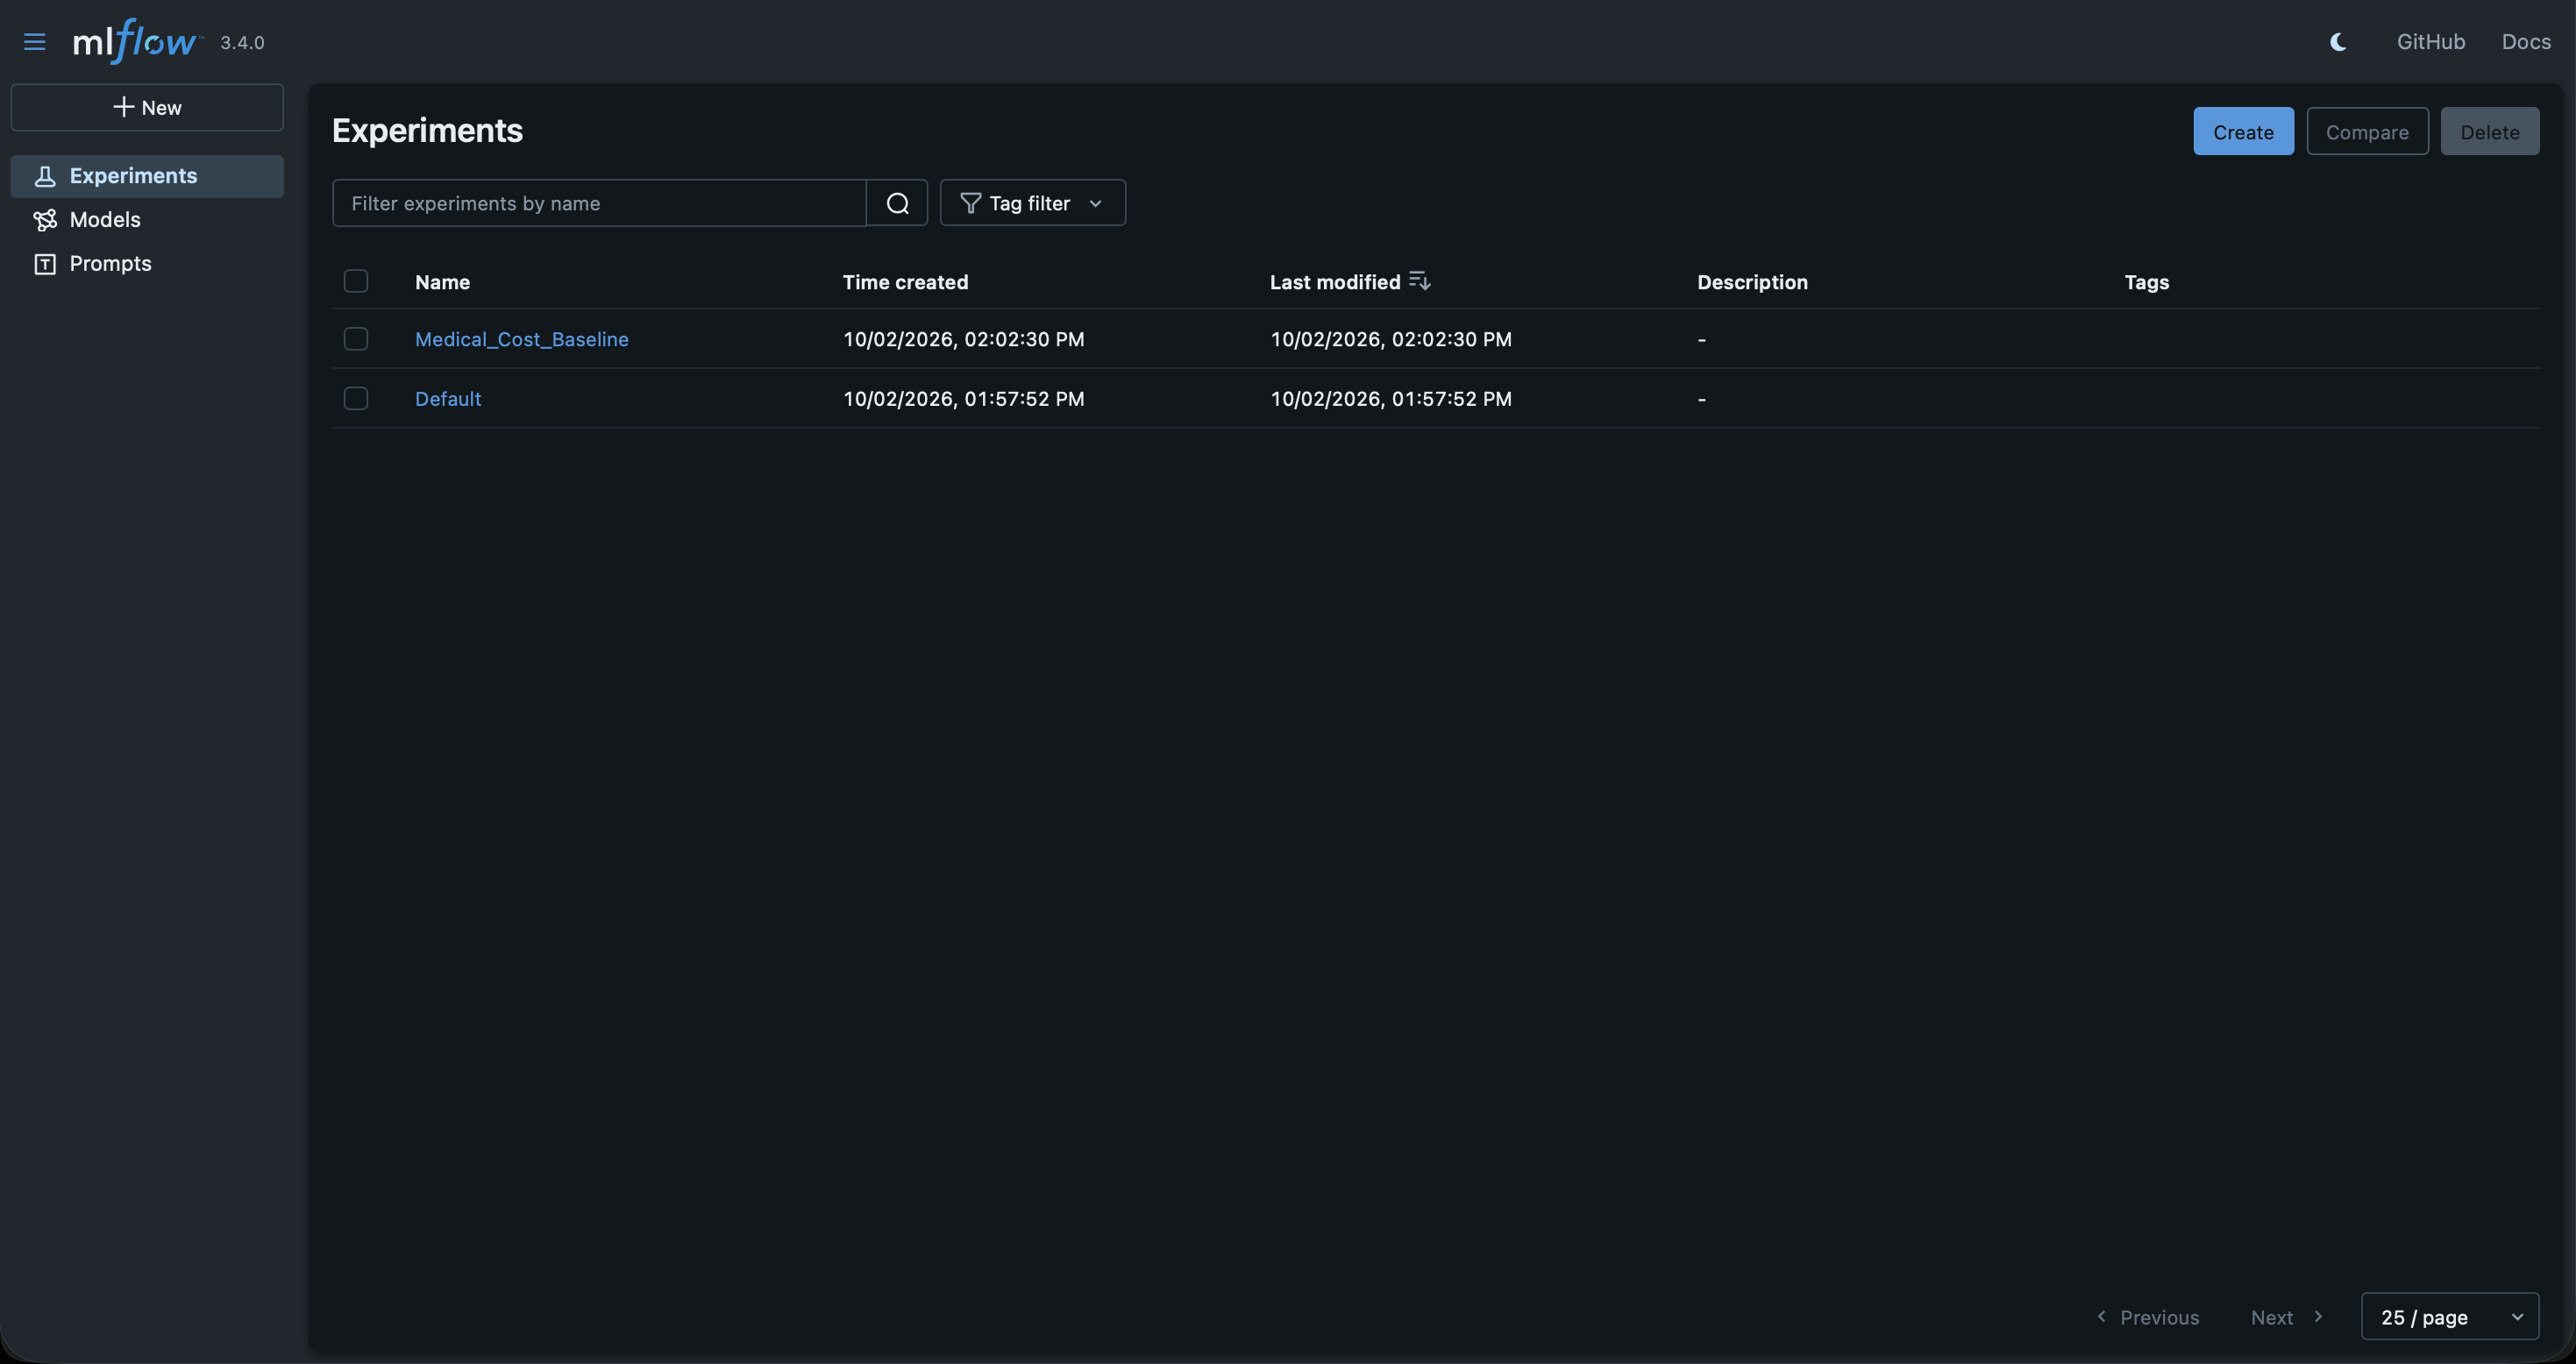
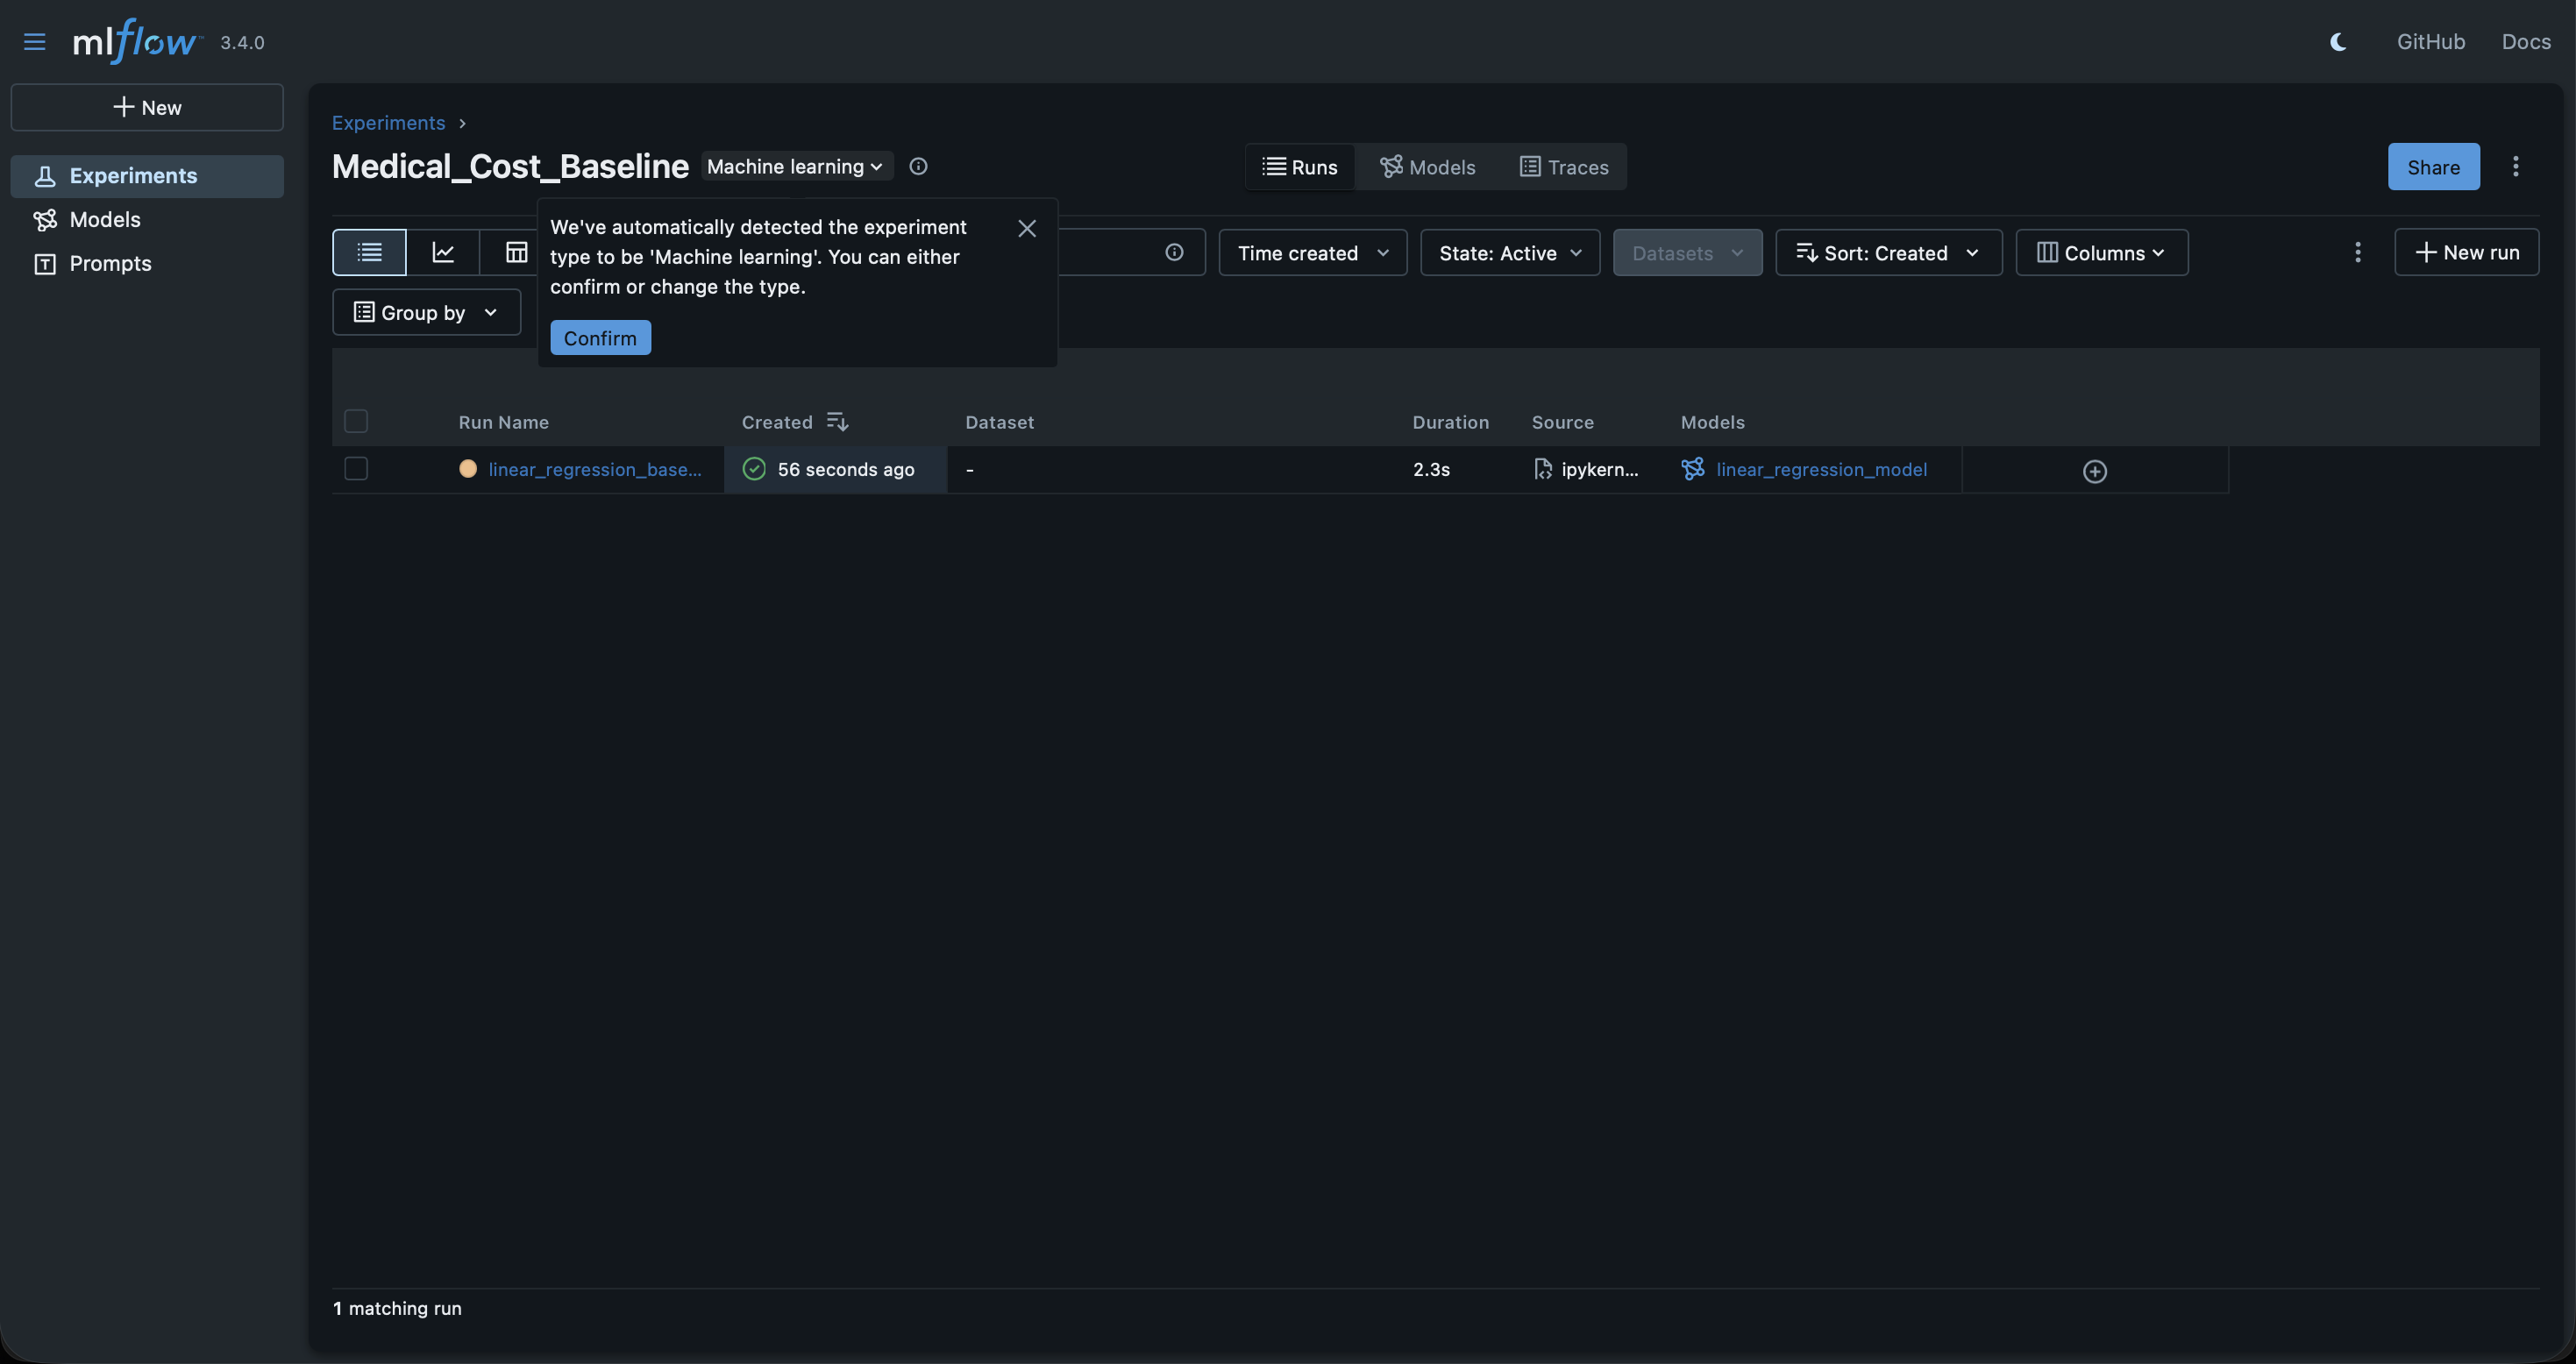
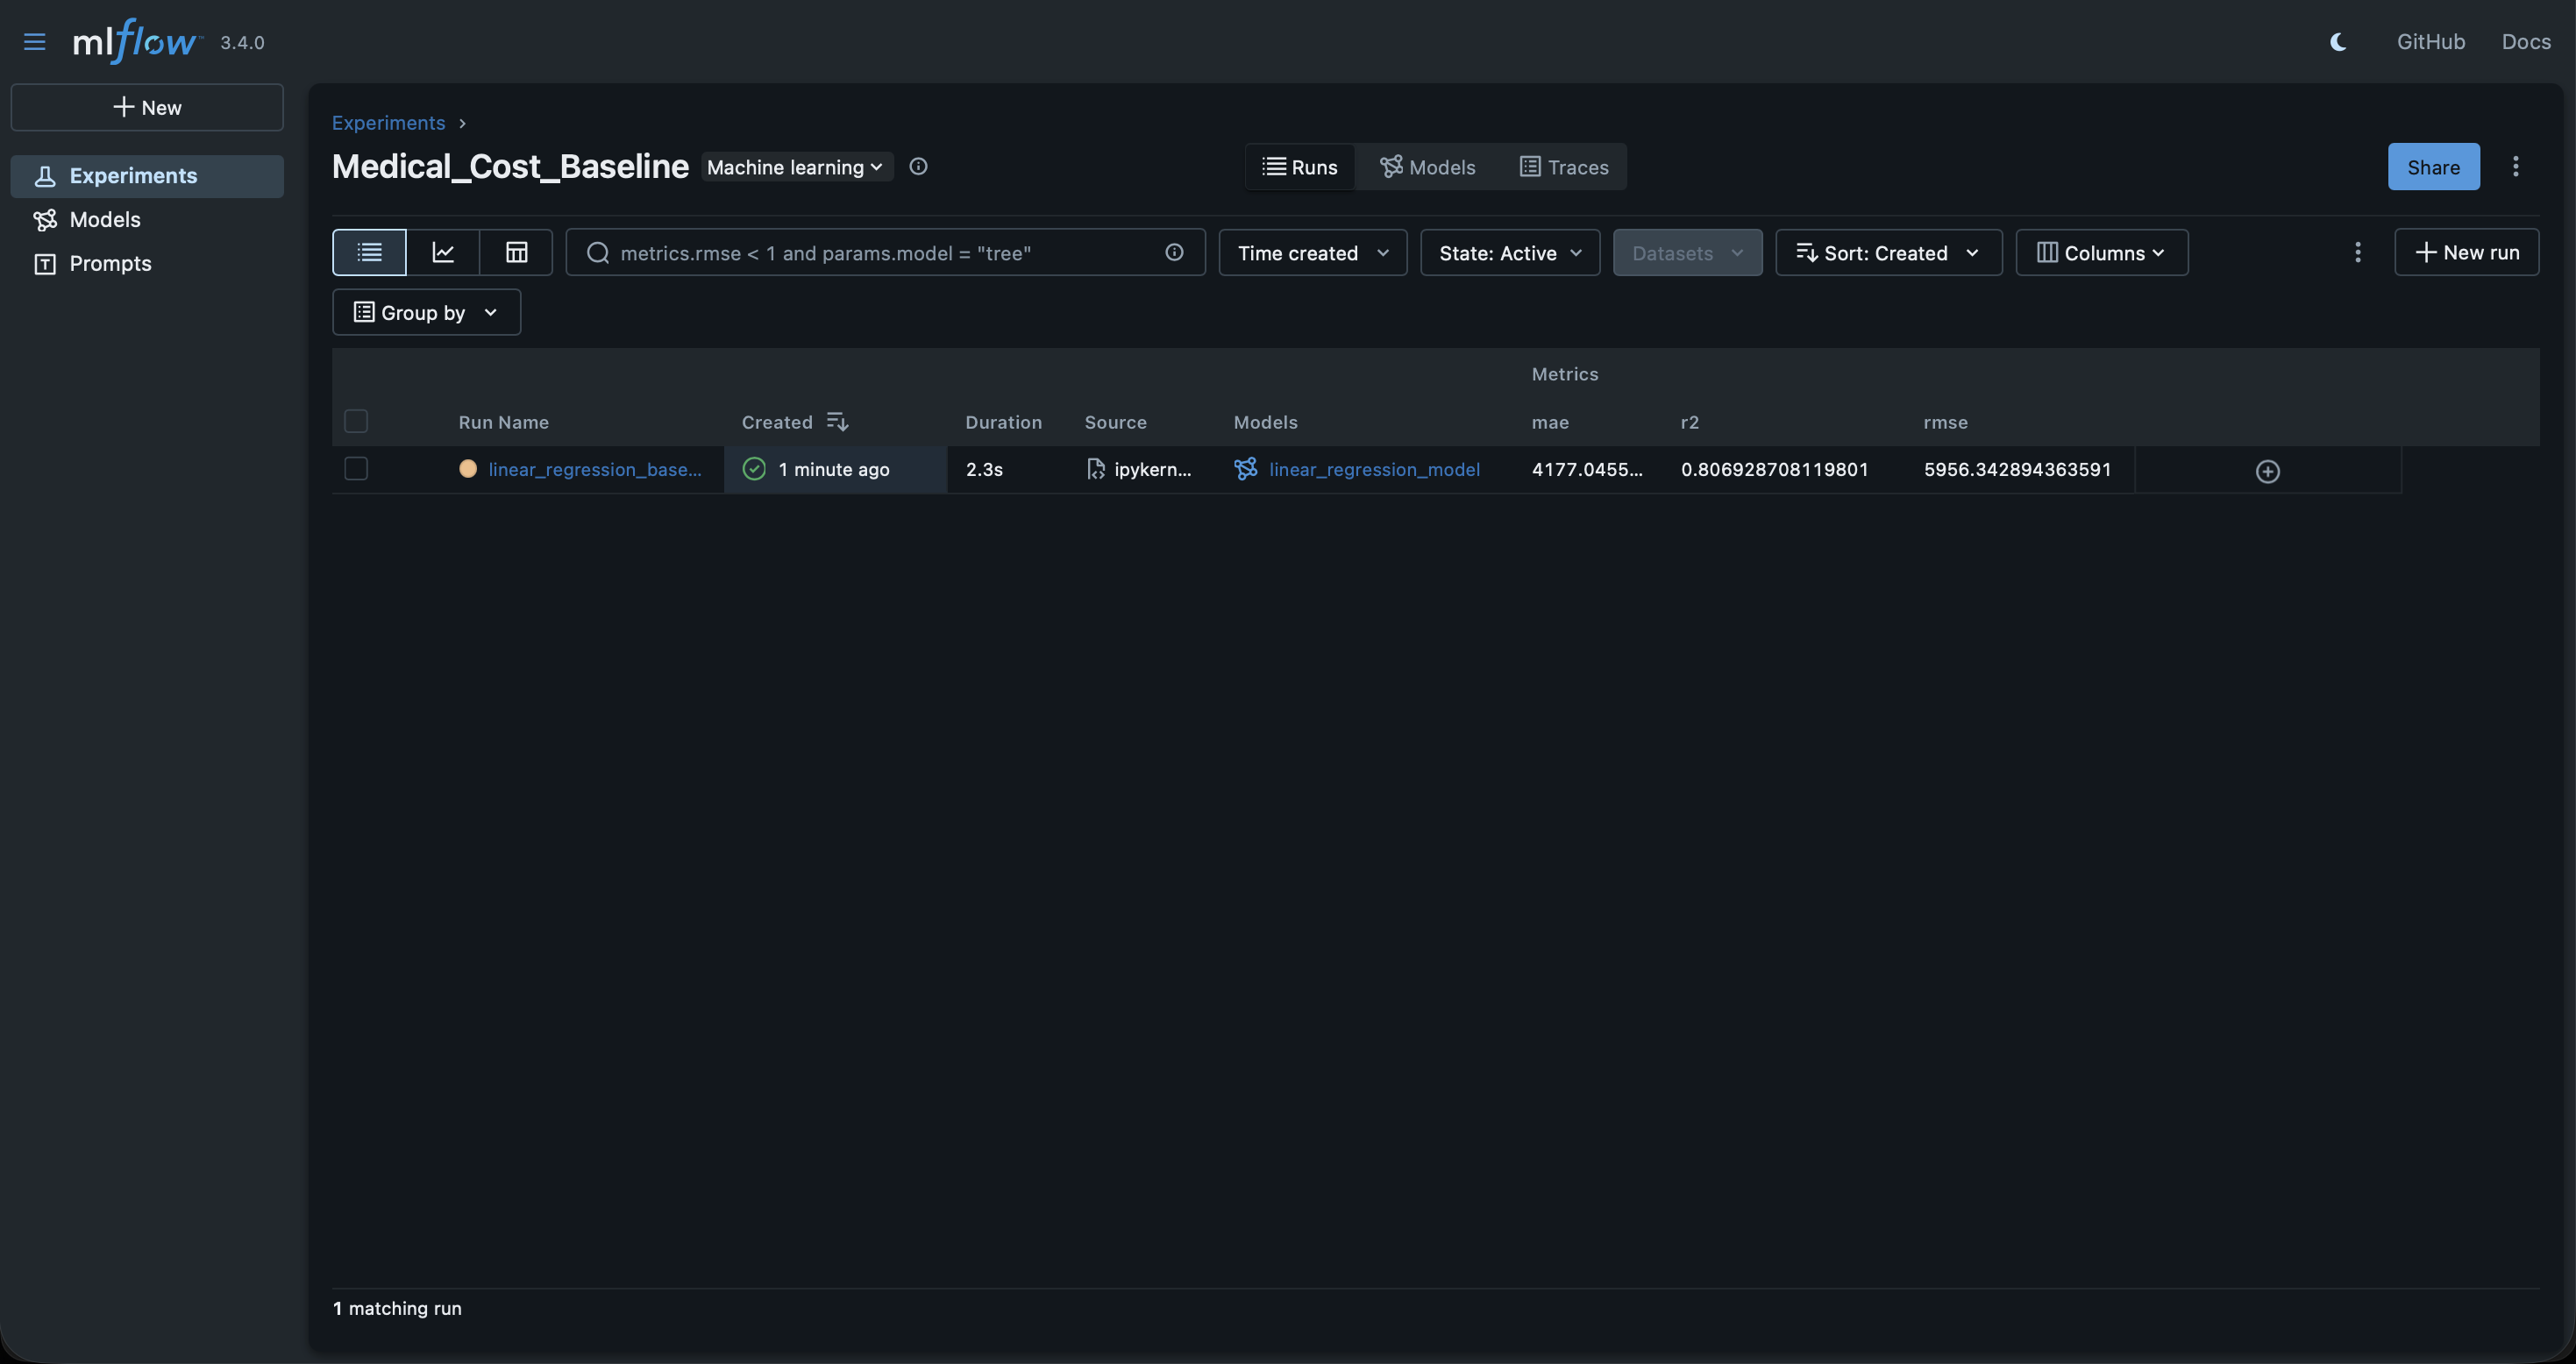
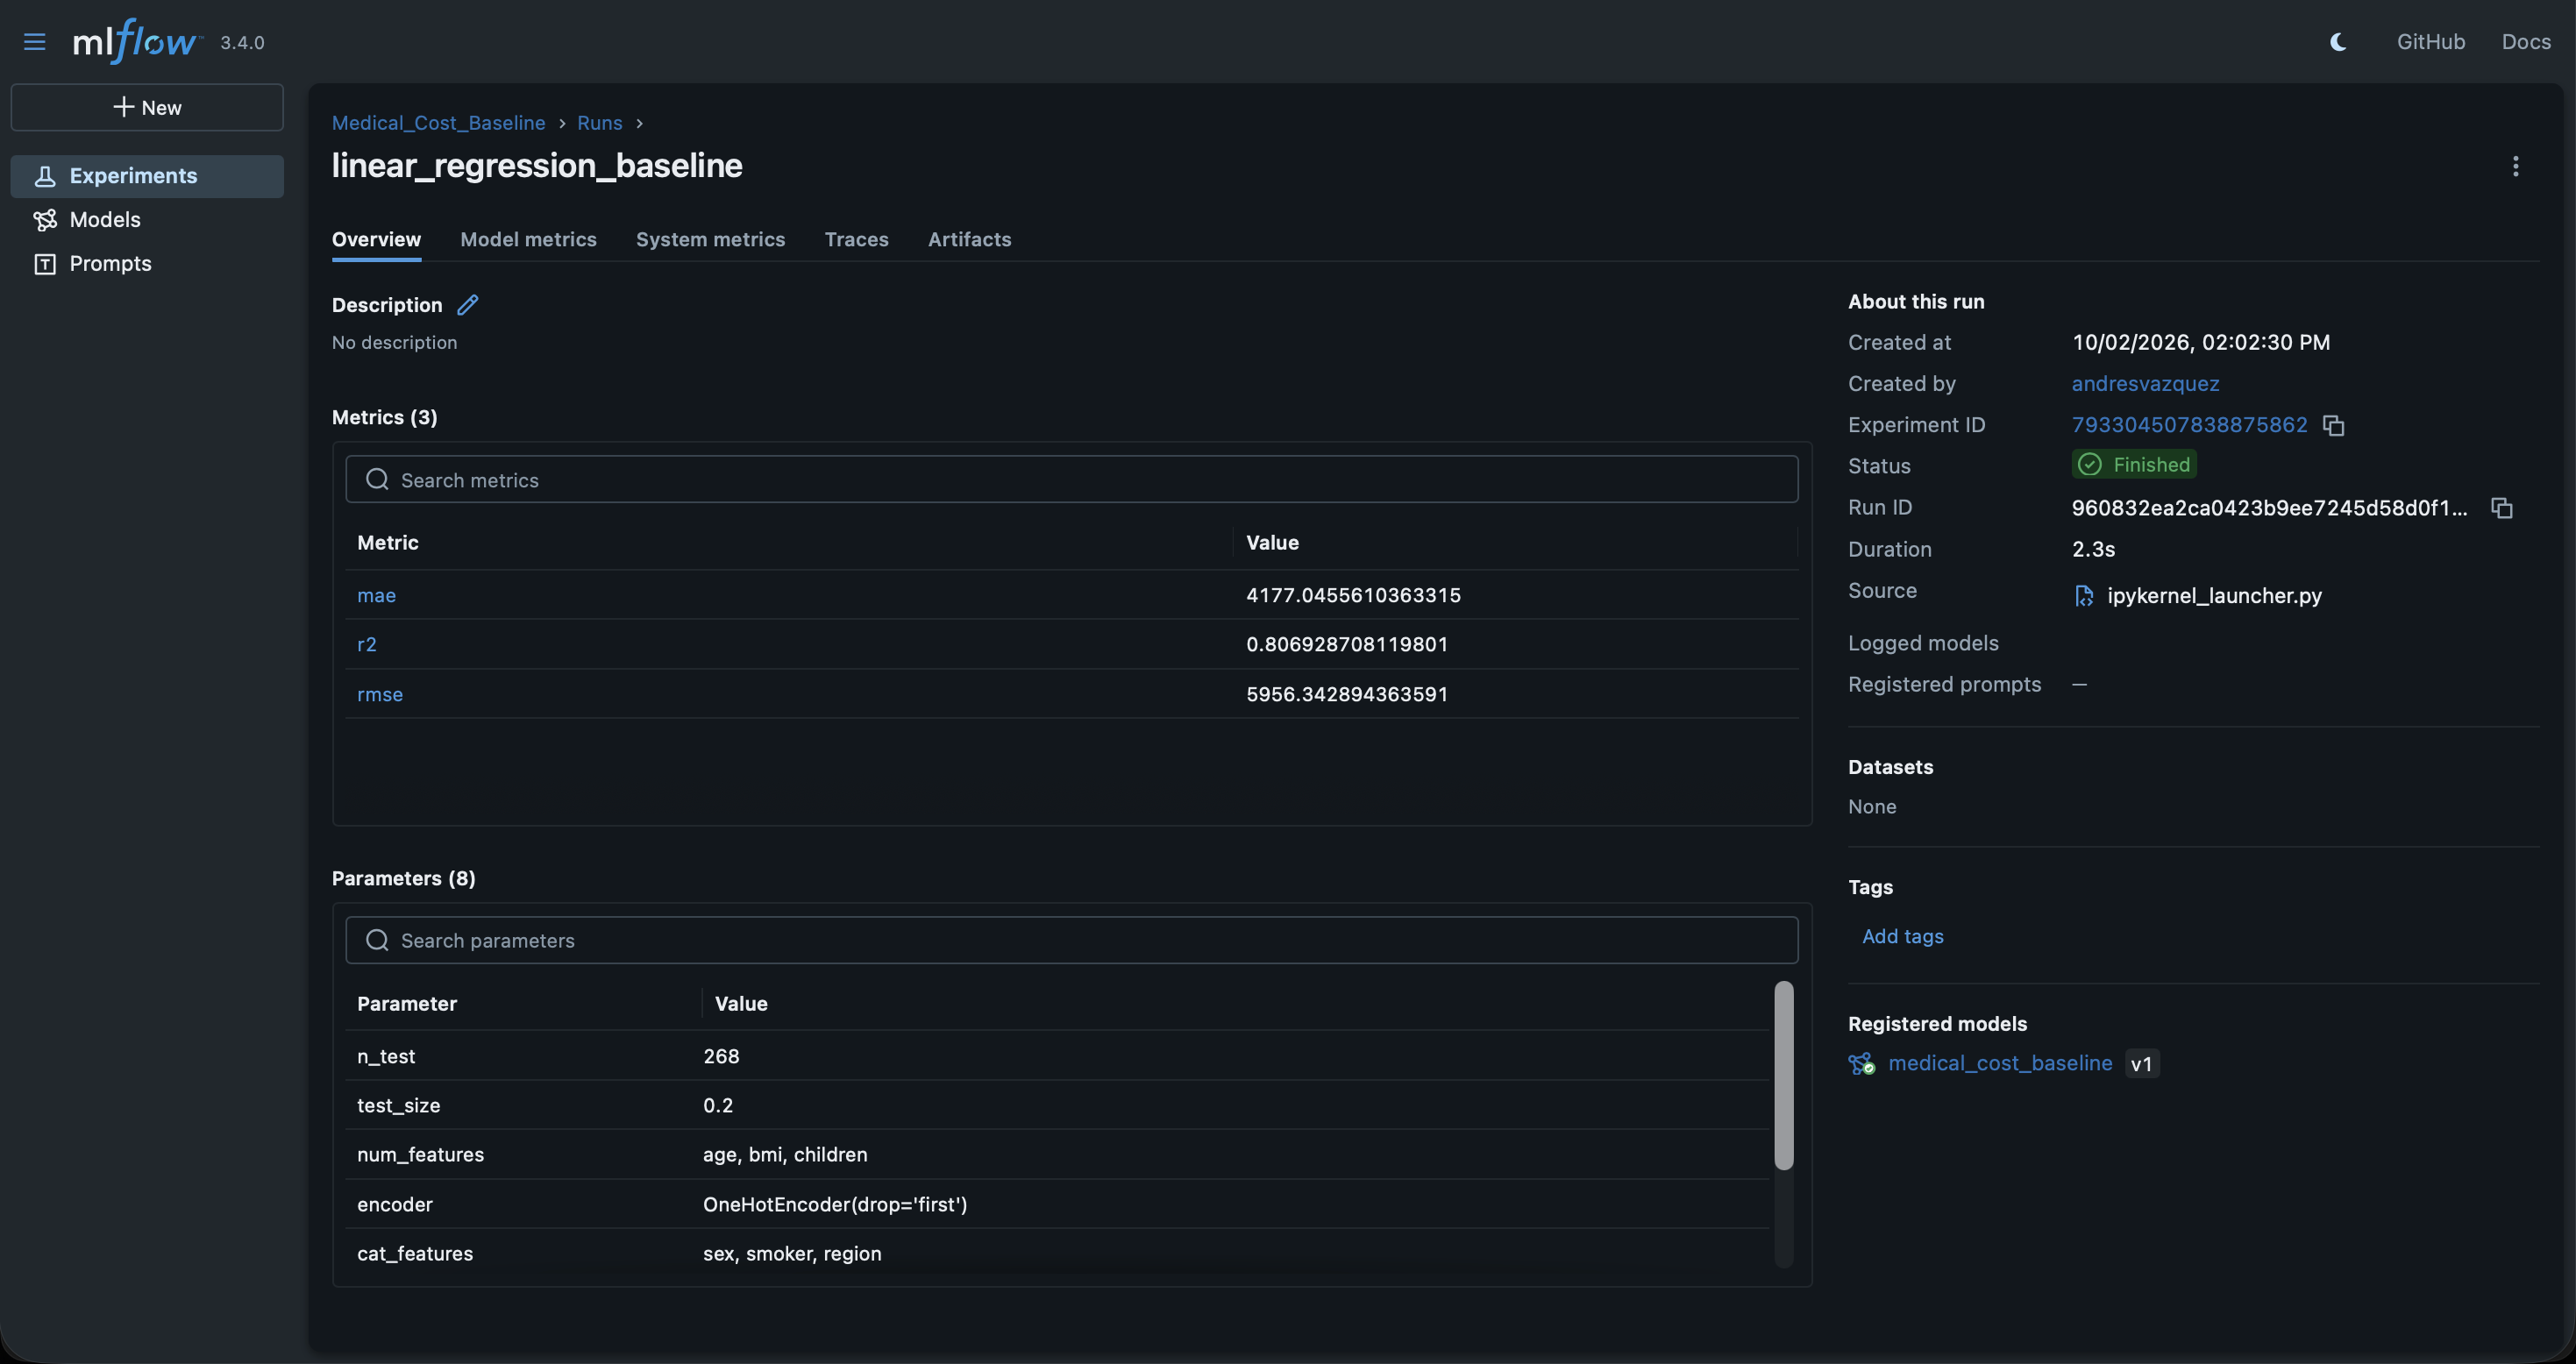
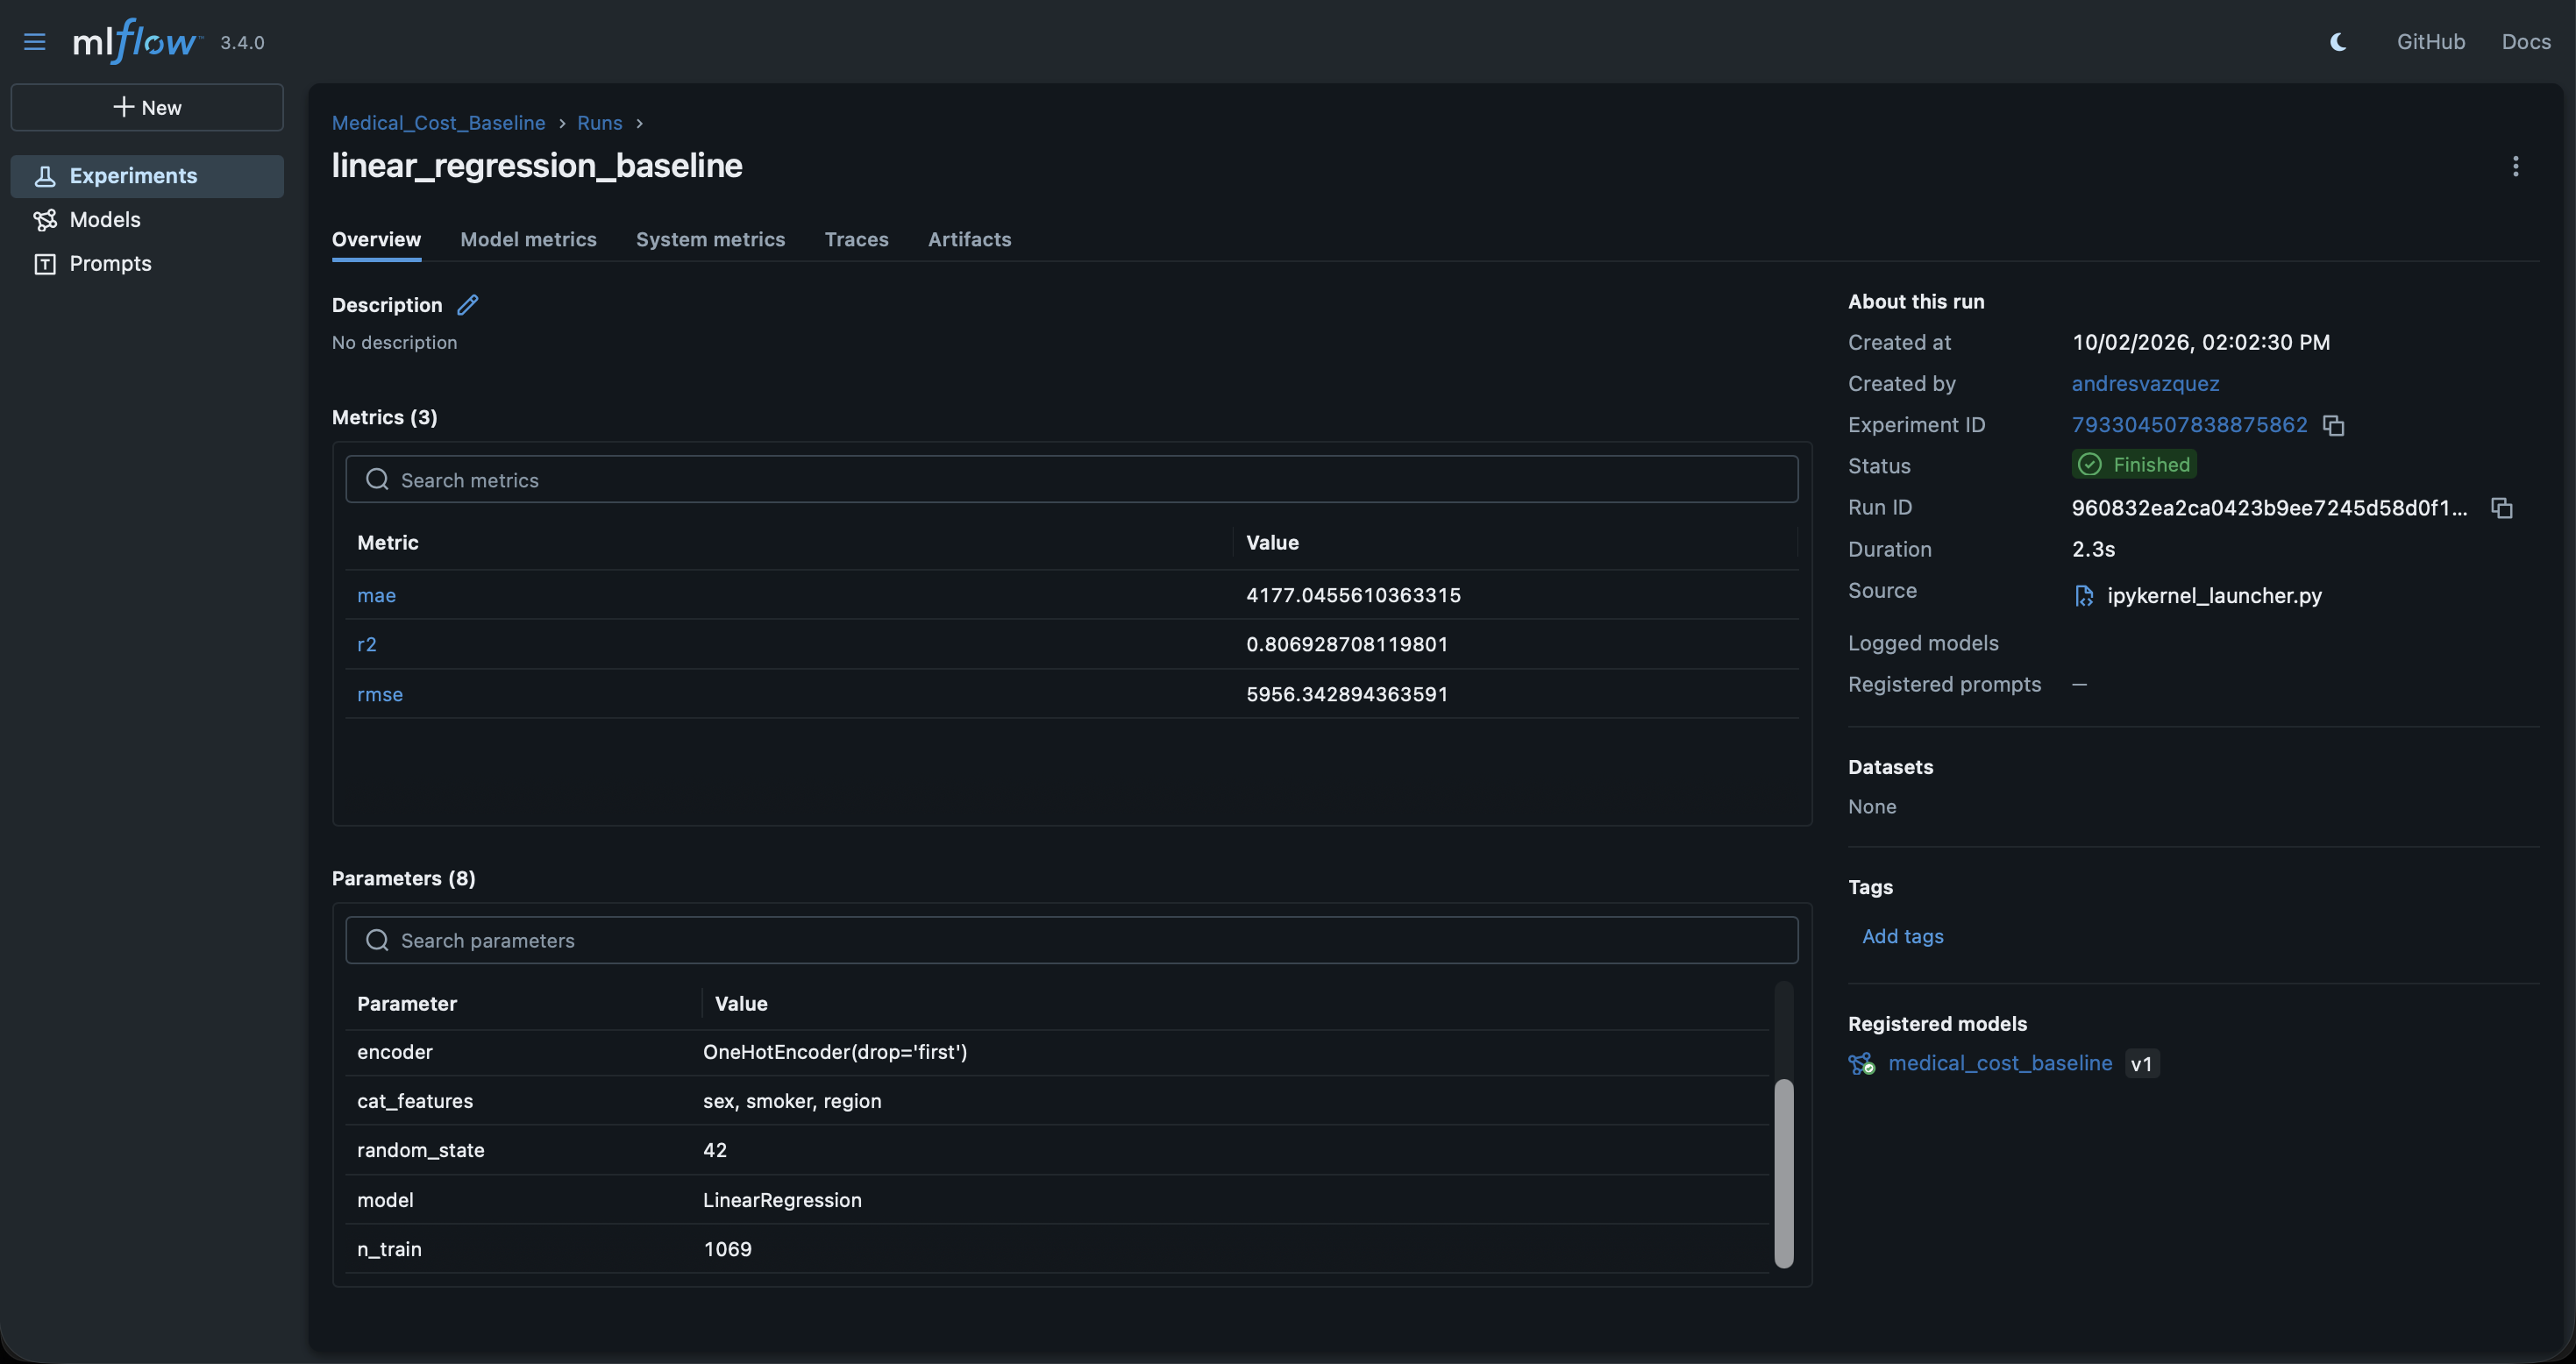
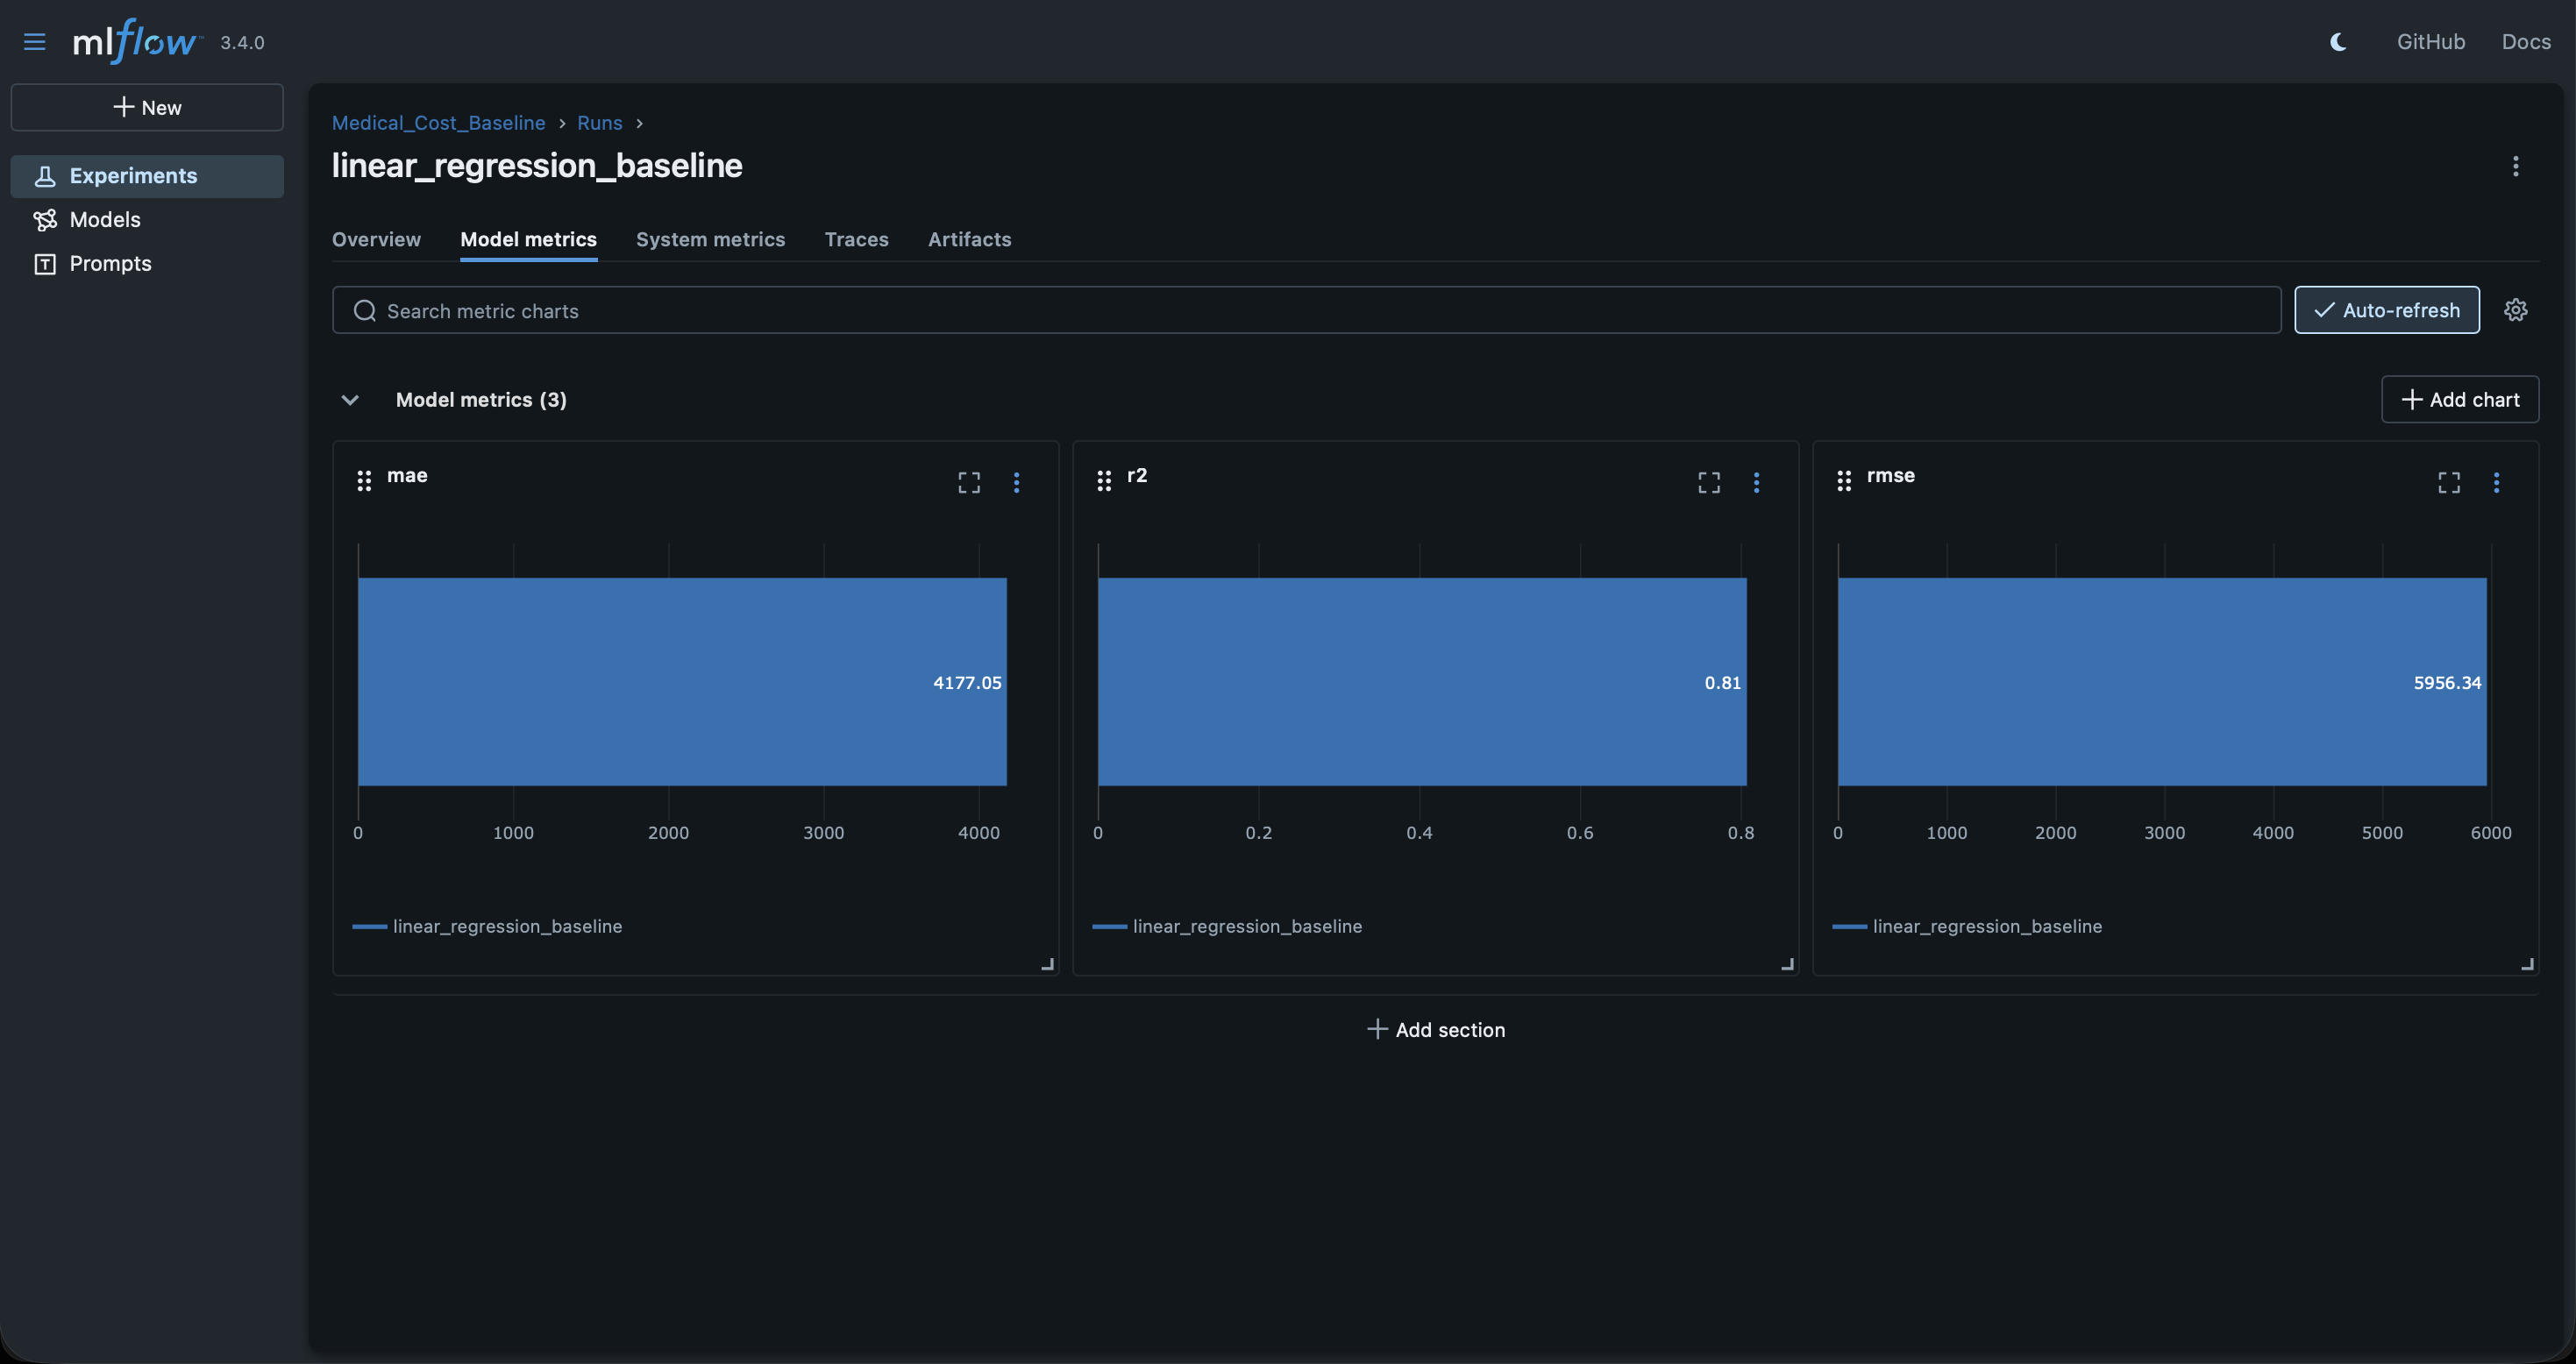
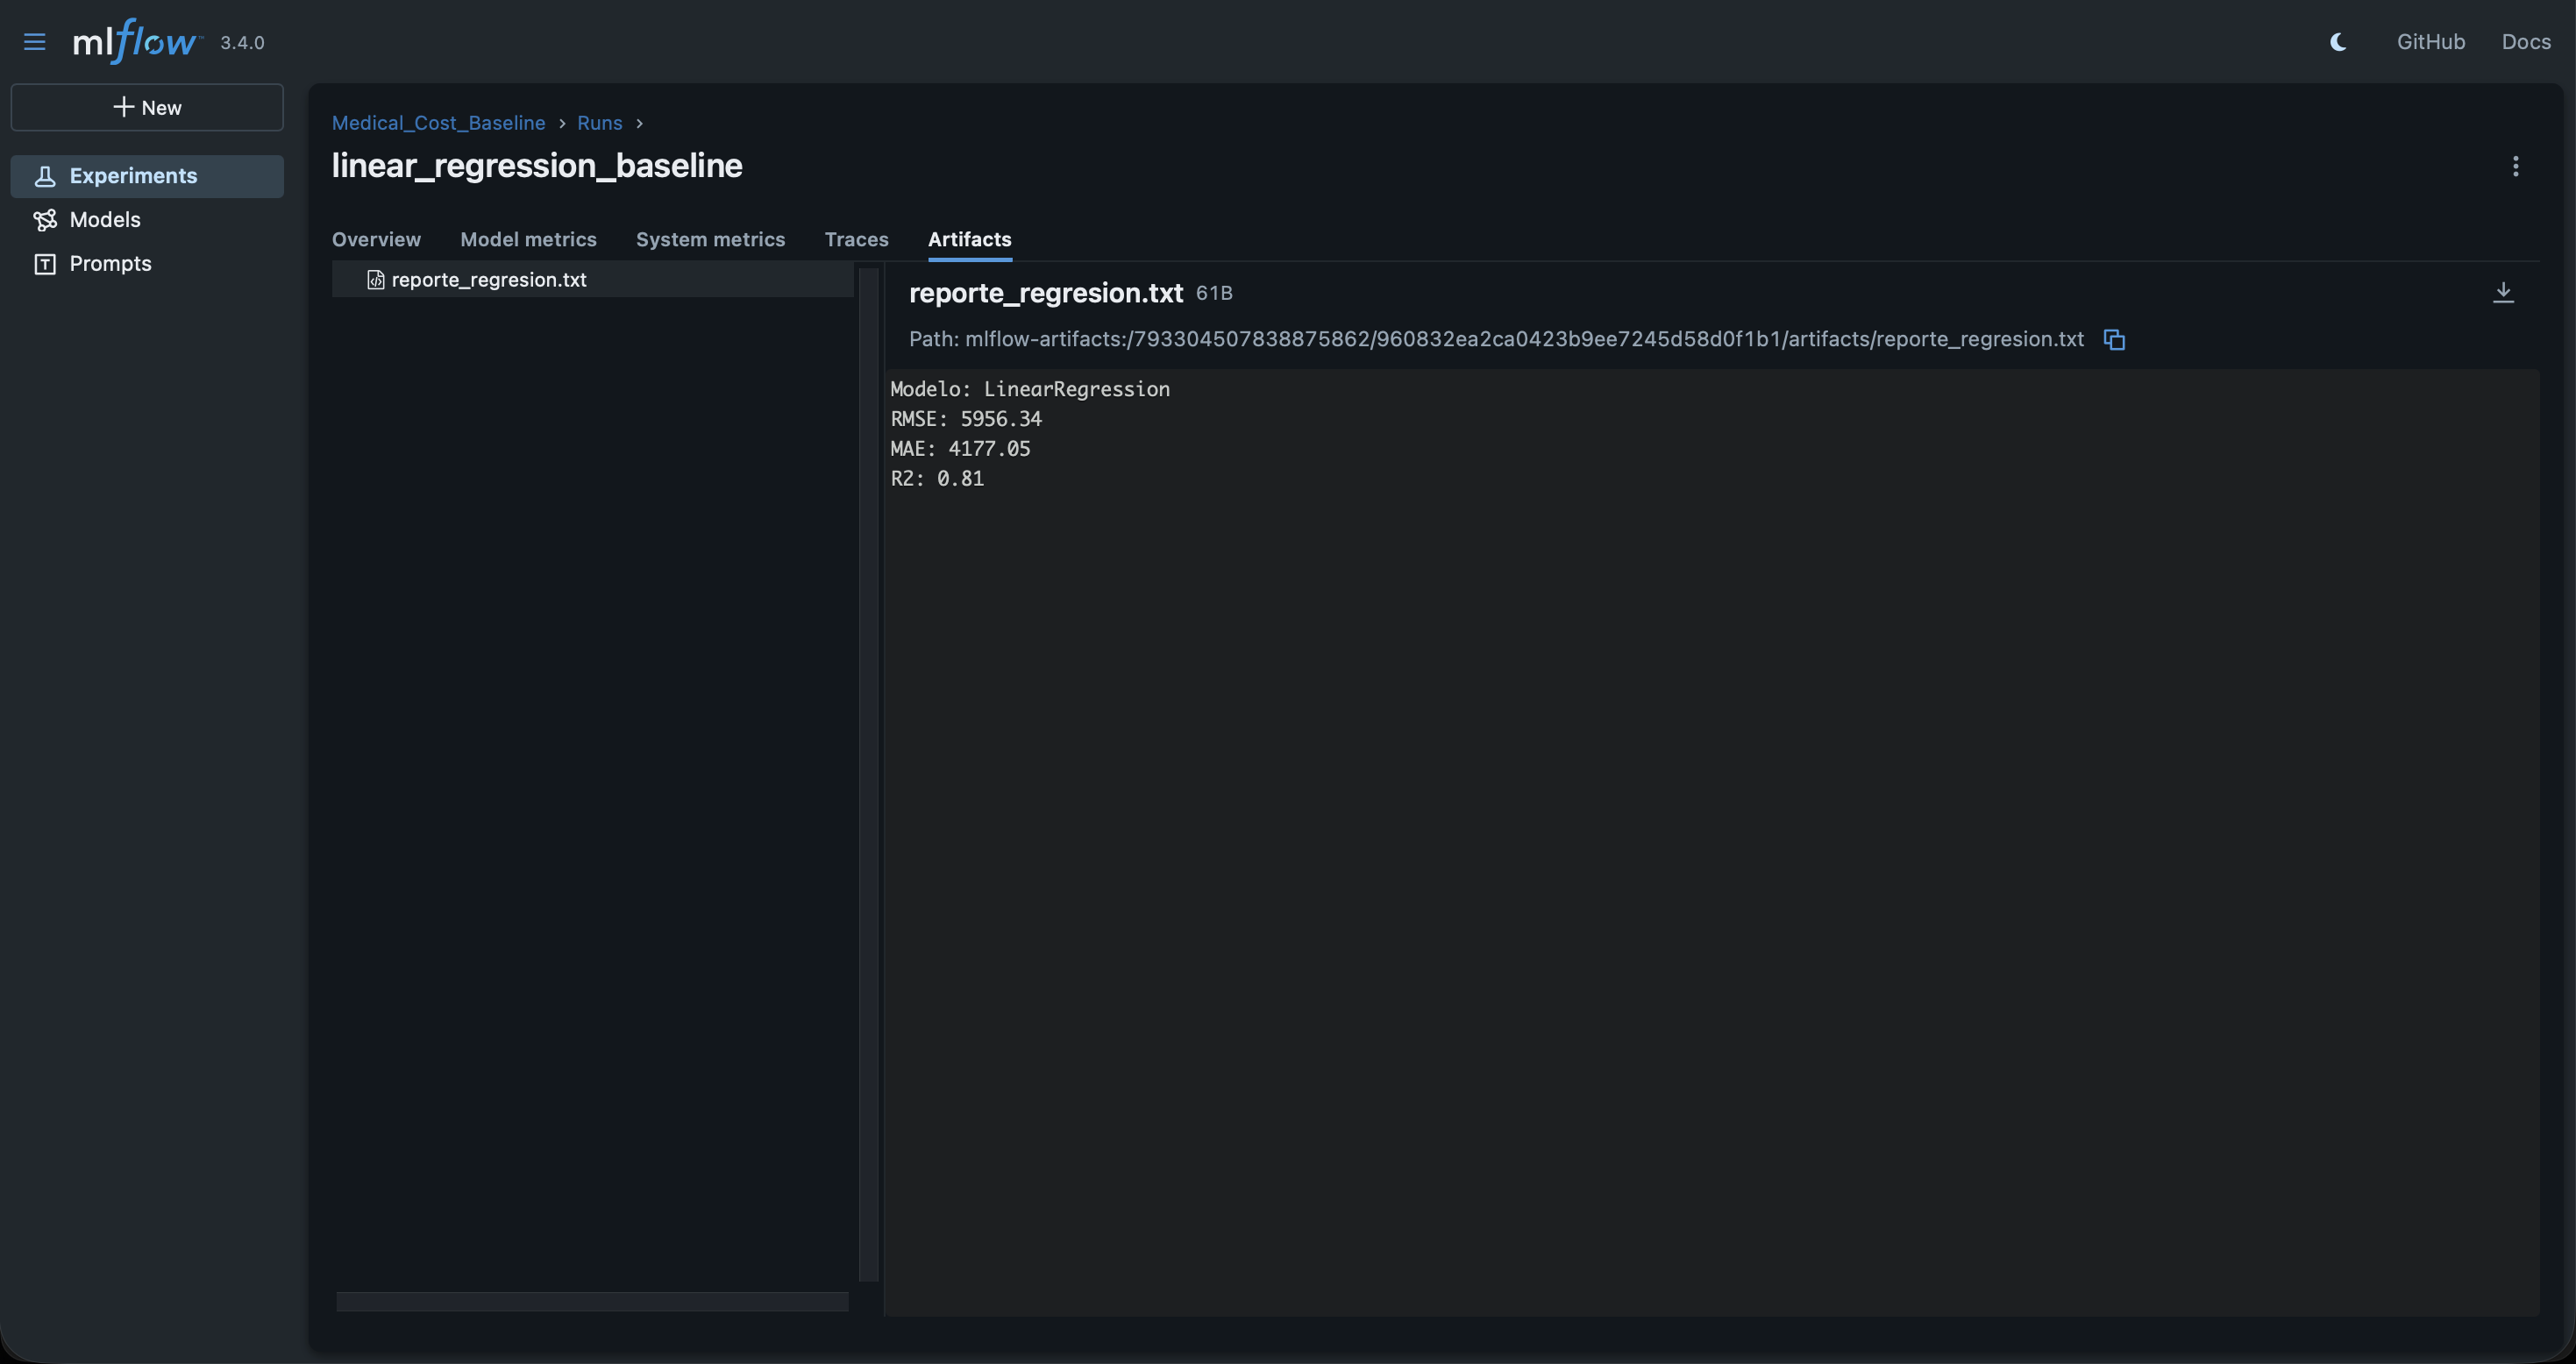
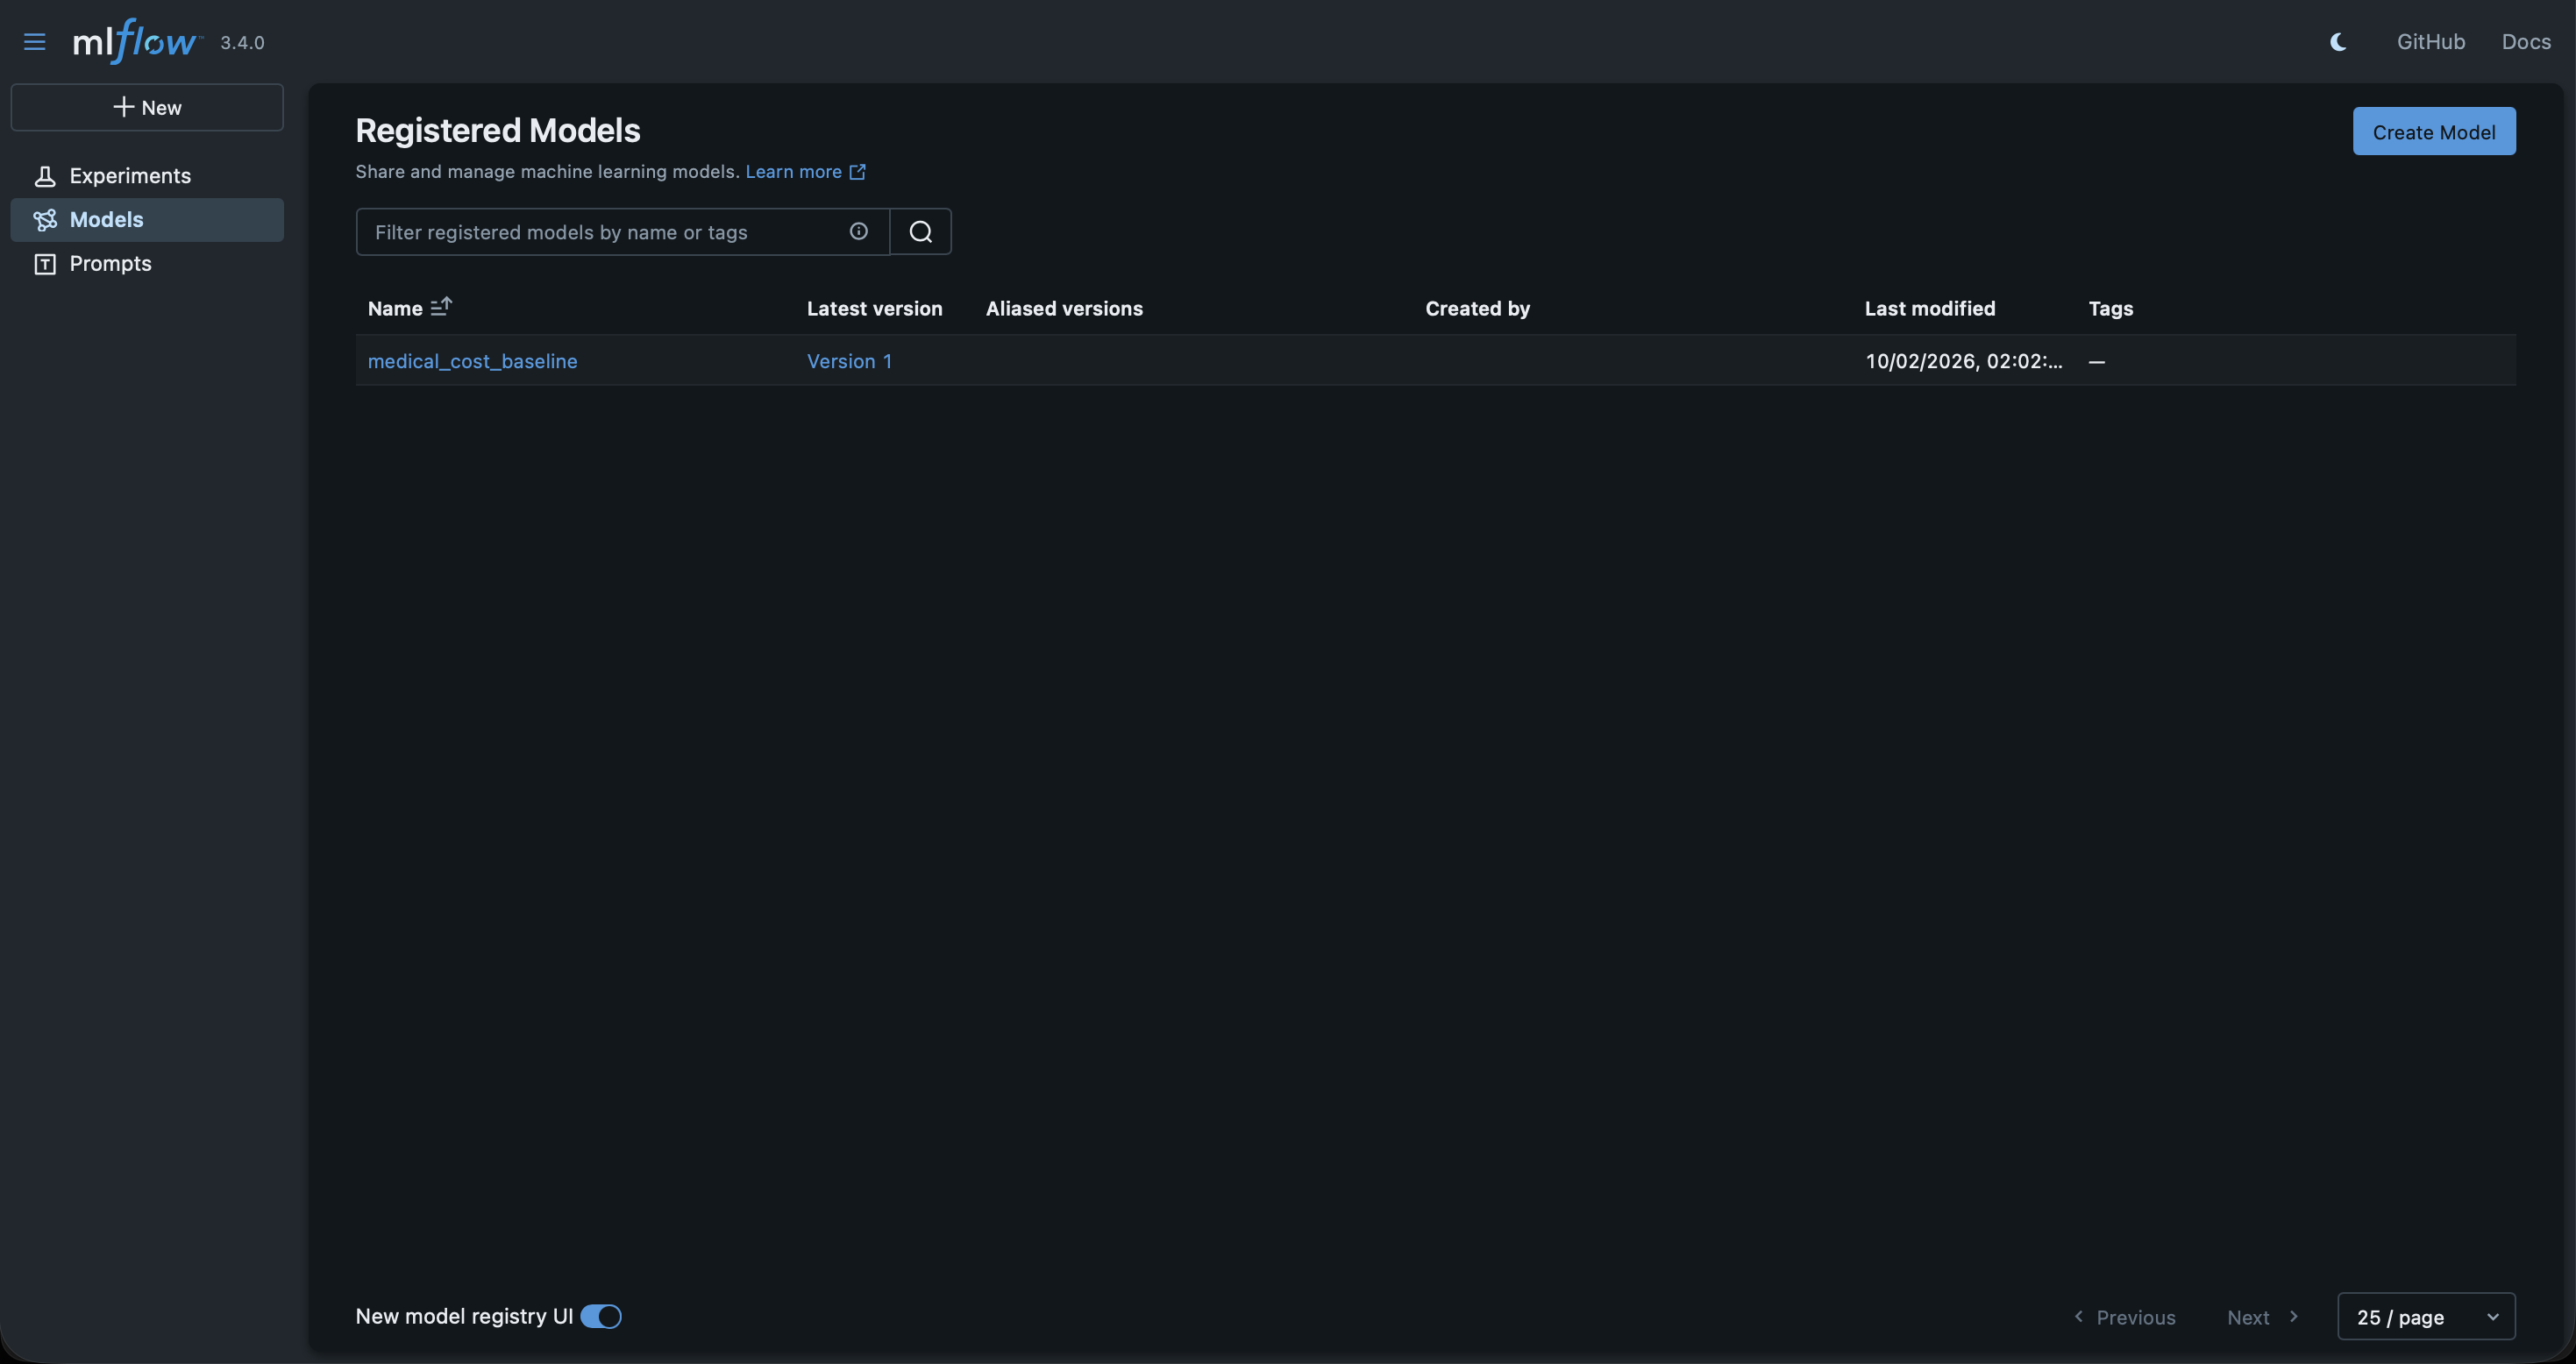
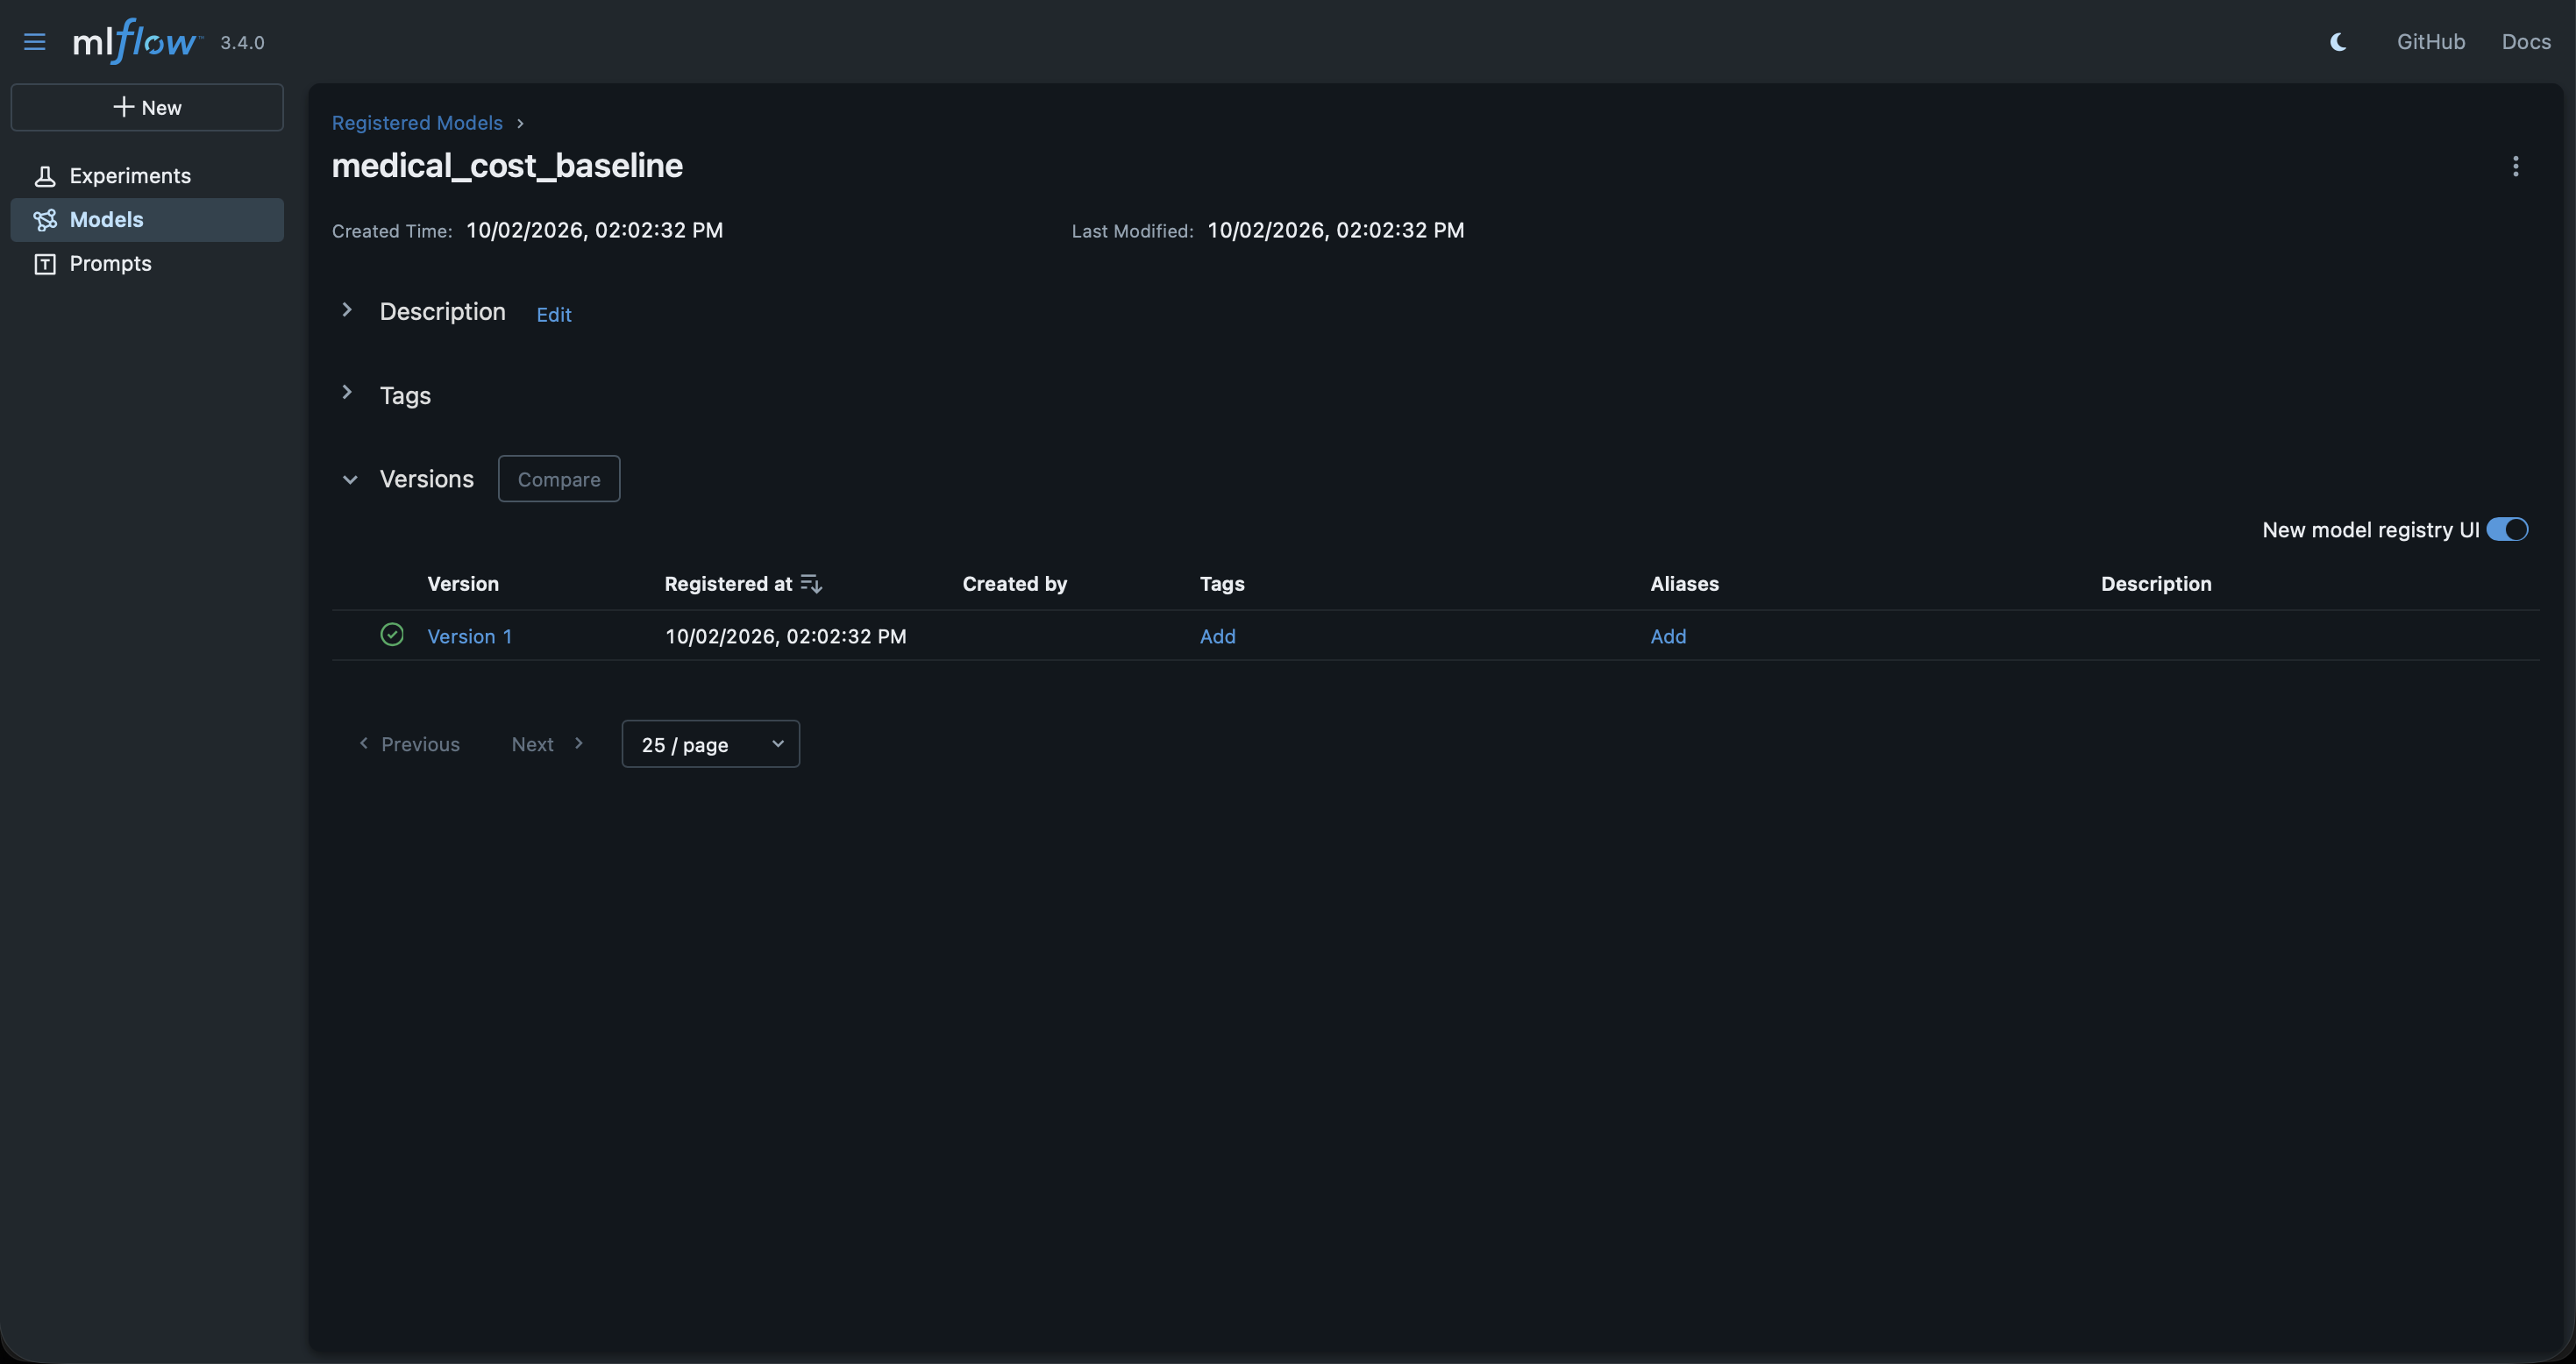
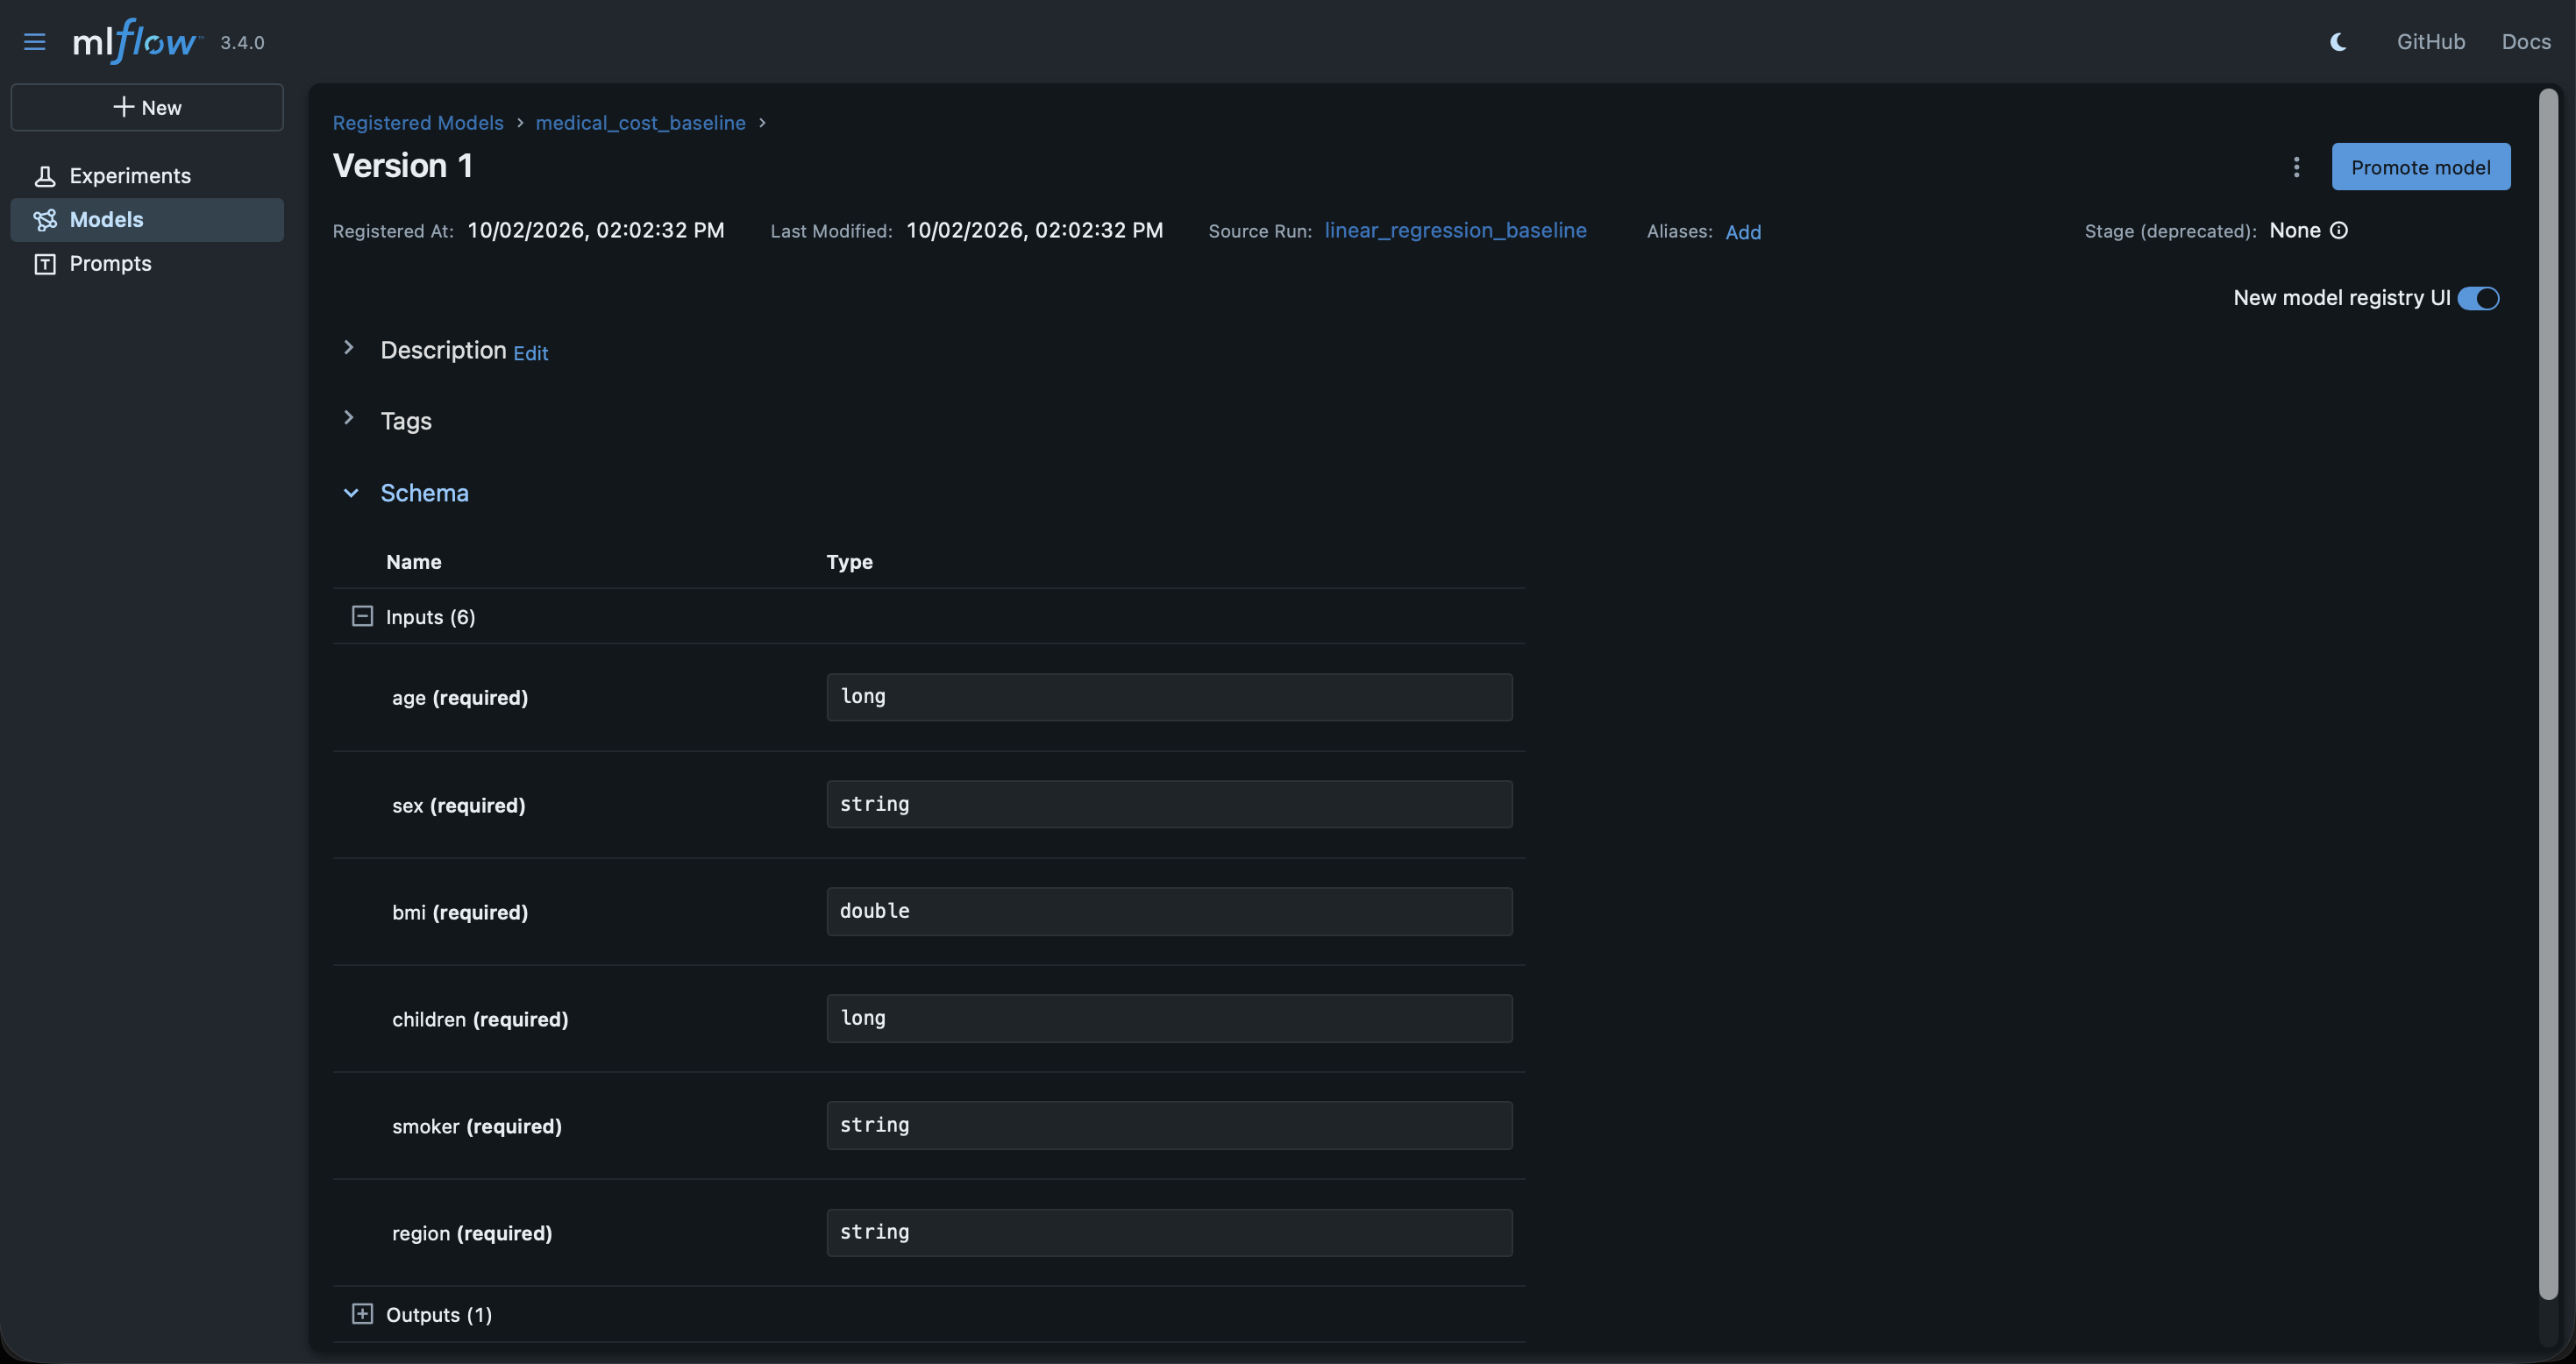
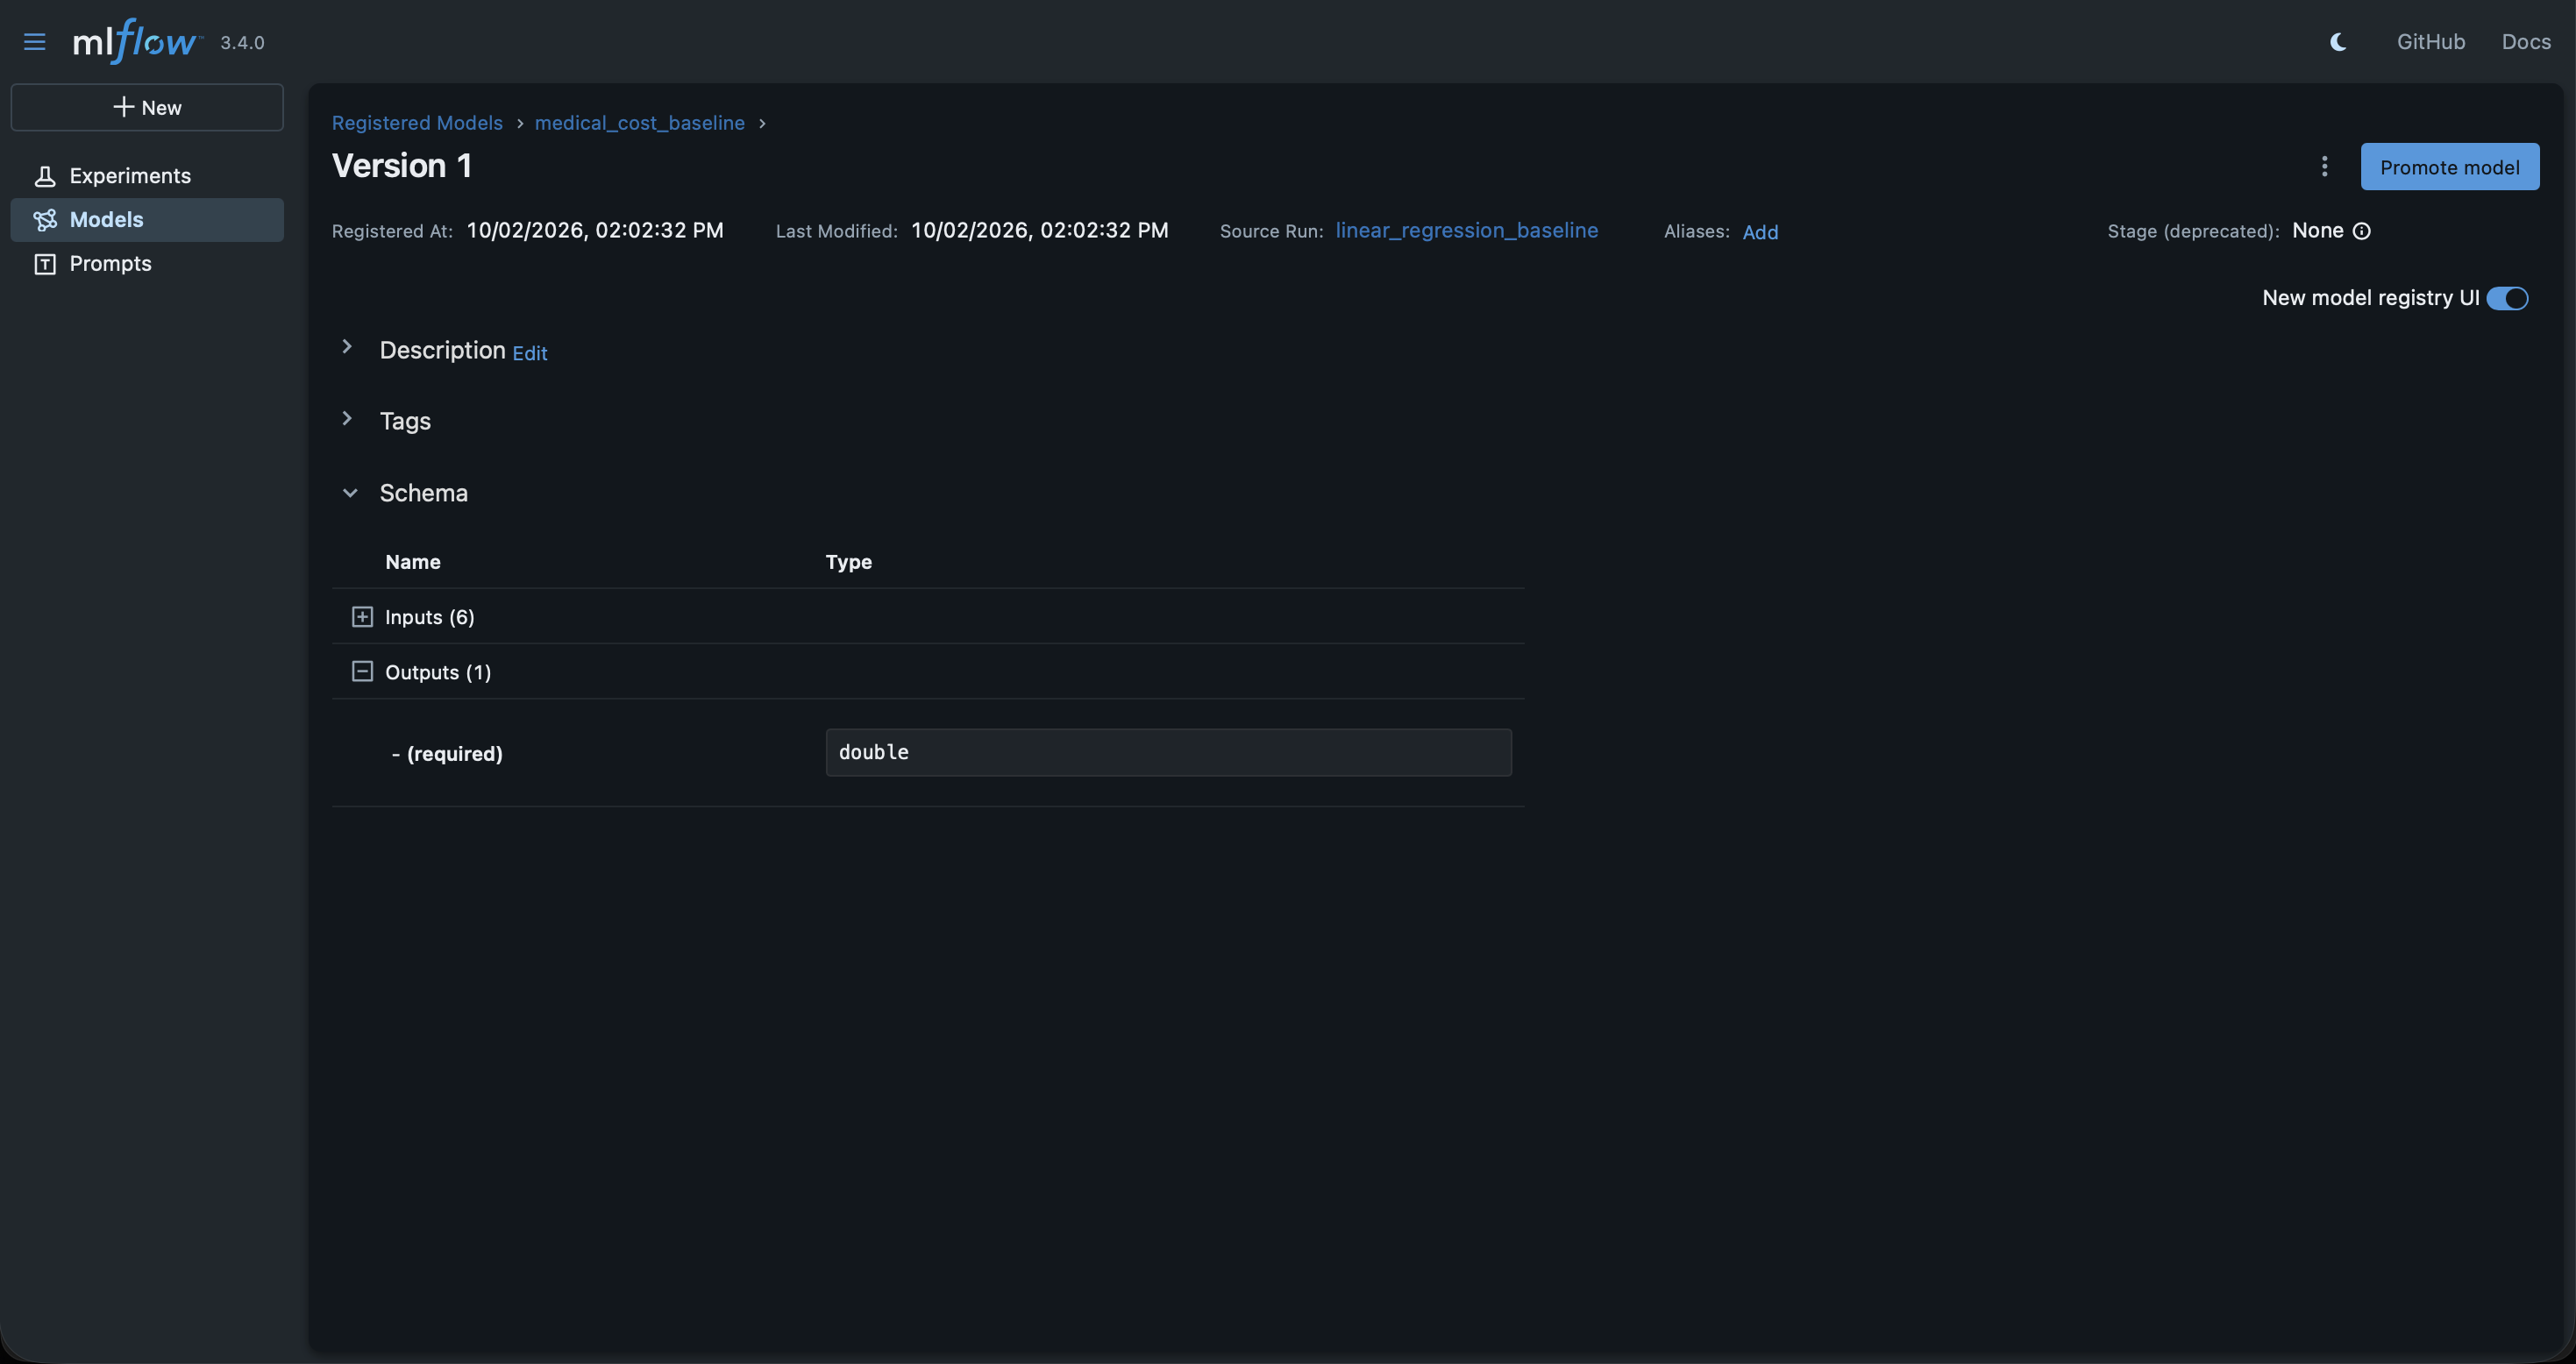

En caso de no poder visualizar las capturas, favor de consultar aquí: https://drive.google.com/file/d/1HN1Ehz7HqxAVaaiSTRjyyPCsuLy23tk5/view?usp=share_link

# **Paso 7: Reflexión sobre MLOps**

Pensando en las prácticas de MLOps, en este flujo el trabajo quedó reproducible solo en parte: fijé `random_state`, empaqueté el preprocesamiento y el modelo en un `Pipeline` y registré parámetros y métricas en MLflow, pero todavía existe la dependencia de que esto está en local en mi máquina (la libreta) y ejecutar las celdas en orden. Aplicando prácticas de MLOps mejoraría cuatro cosas; Primero, versionaría los datos (por ejemplo con DVC) junto con el código en Git, porque estoy descargando y cargando el dataset directamente desde Kaggle y si hay un cambio en `insurance.csv` pasaría sin dejar rastro y el RMSE ya no sería comparable. Segundo, convertiría la limpieza, el entrenamiento y la evaluación en scripts de un pipeline automatizado en lugar de celdas manuales, con pruebas que revisen faltantes, duplicados y tipos antes de entrenar. Tercero, registraría el modelo en el Model Registry de MLflow con un alias, para poder comparar versiones contra este baseline y regresar a la anterior si una nueva empeora. Cuarto, fijaría las versiones de las librerías en un `requirements.txt` para evitar temas de incompatibilidad y depreciaciones en otras versiones de las mismas y por último pensando a futuro, monitorearía el error del modelo con datos nuevos para detectar drift.

En mi trabajo actual, entre mis actividades de desarrollo de software, tengo un proyecto de desarrollo de un modelo de predicción de ventas por modelo de vehículo para una plataforma de distribuidores automotrices. Ahí me sirve exactamente este flujo: partir de una línea base, dividir bien los datos, medir con métricas coherentes y dejar registrado cada experimento con sus parámetros y métricas. Con las herramientas que he aprendido en este curso, MLflow me sería útil para comparar de forma objetiva cada ajuste de hiperparámetros contra el modelo que está en producción, en lugar de depender de notas sueltas, y así justificar cualquier cambio con evidencia.